# TR-HASH : comparaison des modèles

Quatre modèles, les mêmes données et sept seeds pour comparer l’apprentissage et la rétention.


## 1. Configuration

`Exécuter tout` entraîne les quatre modèles depuis zéro. Pour consulter un résultat enregistré, mettre `RUN_QUALIFICATION=False` et renseigner `RUN_DIRECTORY`.


In [ ]:
from types import SimpleNamespace
import random
import torch
from torch import nn
import torch.nn.functional as F

MARGE = 0.001

METRIQUES = ("lm_pretrain", "lm_refinement", "lm_final", "reponses_finales", "oubli")

SEED_DONNEES = 42

config = SimpleNamespace(
    vocab_size=256,
    hidden_size=64,
    num_hidden_layers=2,
    num_attention_heads=4,
    num_key_value_heads=1,
    max_position_embeddings=256,
    num_experts=4,
    top_k=2,
)

protocole = {
    "pretraining": {"epochs": 2, "lr": 1e-3},
    "refinement": {"epochs": 1, "lr": 5e-4},
    "sft": {"epochs": 12, "lr": 2e-4},
}

options_adamw = {"betas": (0.9, 0.999), "eps": 1e-8, "weight_decay": 0.01}




def fixer_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)


def lineaire(entree, sortie, residuel=False):
    couche = nn.Linear(entree, sortie, bias=False)
    std = 0.02 / ((2 * config.num_hidden_layers) ** 0.5 if residuel else 1)
    nn.init.normal_(couche.weight, std=std)
    return couche


class SwiGLU(nn.Module):
    def __init__(self, largeur):
        super().__init__()
        self.gate = lineaire(config.hidden_size, largeur)
        self.up = lineaire(config.hidden_size, largeur)
        self.down = lineaire(largeur, config.hidden_size, residuel=True)

    def forward(self, x, token_ids=None):
        return self.down(F.silu(self.gate(x)) * self.up(x))


SEEDS_DEV = (42, 123, 314, 159, 265, 358, 979)



from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import json
import os
import shutil
import time

RUN_QUALIFICATION = True
ALLOW_DOWNLOAD = True
RUN_DIRECTORY = None  # Lecture seule : False ci-dessus, puis chemin d'un ancien résultat ici.
DATA_CACHE = Path.cwd() / "artifacts/tr_hash/data_raw"
ARTIFACTS_ROOT = Path.cwd() / "artifacts/tr_hash/qualification"
SEEDS = (42, 123, 314, 159, 265, 358, 979)
MODEL_NAMES = ("tr_hash", "dense", "dense_upgraded", "learned_moe")
MODEL_PARAMETERS = dict(zip(MODEL_NAMES, (110976, 110976, 110976, 111488)))
ROUTER_SEED_OFFSET = 1_000_003
STAGES = protocole


## 2. Modèles

Chaque modèle utilise deux couches de largeur 64 et une attention GQA à quatre têtes Q et une tête KV.

| Modèle | Architecture MLP | Paramètres |
|---|---|---:|
| TR-HASH | Branche partagée et quatre experts, deux routes composées par token | 110 976 |
| Dense | SwiGLU dense, attention standard | 110 976 |
| Dense amélioré | SwiGLU dense, mêmes têtes routées et V0 que TR-HASH | 110 976 |
| MoE inspiré de Qwen | Branche partagée et quatre experts, deux routes apprises par token | 111 488 |


In [ ]:
def decaler_lag(ids, decalage):
    if ids.shape[1] <= decalage:
        return torch.zeros_like(ids)
    return torch.cat((torch.zeros_like(ids[:, :decalage]), ids[:, :-decalage]), dim=1)


def calculer_routes_mlp(tokens, couche, precedent=None, avant_precedent=None):
    if precedent is None:
        precedent = torch.zeros_like(tokens)
    if avant_precedent is None:
        avant_precedent = torch.zeros_like(tokens)
    contexte = (precedent + 5 * avant_precedent) % 9
    if couche == 1:
        primaire = ((tokens + 1) % 4) ^ (2 * ((contexte % 3) % 2))
        pas = 1 + (tokens // 4 + 2 * (contexte // 3) + 1) % 3
    else:
        primaire = (tokens + couche) % 4
        pas = 1 + (tokens // 4 + (1 + couche % 2) * (contexte % 3) + couche) % 3
    return torch.stack((primaire, (primaire + pas) % 4), dim=-1)


def routes_mlp(ids, couche):
    return calculer_routes_mlp(ids, couche, decaler_lag(ids, 1), decaler_lag(ids, 2))


def calculer_routes_tetes(tokens, couche):
    if couche == 1:
        primaire = (tokens // 12) % 4
        secondaire = (primaire + 1) % 4
    else:
        primaire = (tokens + couche) % 4
        pas = 1 + (tokens // 4 + couche) % 3
        secondaire = (primaire + pas) % 4
    return torch.stack((primaire, secondaire), dim=-1)


def lier_entree_valeur(x, token_ids, couche):
    if couche != 0:
        return x
    canaux = torch.arange(64, dtype=torch.long, device=token_ids.device).view(1, 1, 64)
    indices = (canaux + 16 * (token_ids % 4).unsqueeze(-1)) % 64
    return x.gather(-1, indices)


def rope(x):
    longueur, dimension = x.shape[-2:]
    positions = torch.arange(longueur, device=x.device)[:, None]
    frequences = 10000.0 ** (-torch.arange(0, dimension, 2, device=x.device) / dimension)
    angles = positions * frequences
    angles = torch.cat((angles, angles), dim=-1)
    gauche, droite = x.chunk(2, dim=-1)
    return x * angles.cos() + torch.cat((-droite, gauche), dim=-1) * angles.sin()


class TRHashMLP(nn.Module):
    def __init__(self, couche):
        super().__init__()
        self.shared = SwiGLU(128)
        self.experts = nn.ModuleList([SwiGLU(16) for _ in range(4)])
        self.couche = couche
        self.register_buffer("routes", calculer_routes_mlp(torch.arange(256), couche))

    def forward(self, x, token_ids):
        routes = routes_mlp(token_ids, self.couche)
        routee = torch.zeros_like(x)
        for numero, expert in enumerate(self.experts):
            primaire = (routes[..., :1] == numero).to(x.dtype)
            secondaire = (routes[..., 1:2] == numero).to(x.dtype)
            poids = 0.5 * primaire + 0.5 * secondaire
            routee = routee + poids * expert(x)
        return self.shared(x) + 2.0 * routee


class AttentionCausale(nn.Module):
    def __init__(self, couche, attention_routee):
        super().__init__()
        self.attention_routee = attention_routee
        self.couche = couche
        if attention_routee:
            self.register_buffer("routes_tetes", calculer_routes_tetes(torch.arange(256), couche))
        self.h, self.kv, self.d = 4, 1, 16
        self.q = lineaire(64, 64)
        self.k = lineaire(64, 16)
        self.v = lineaire(64, 16)
        self.o = lineaire(64, 64, residuel=True)
        self.norm_q = nn.RMSNorm(16, eps=1e-6)
        self.norm_k = nn.RMSNorm(16, eps=1e-6)

    def forward(self, x, token_ids):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.d).transpose(1, 2)
        k = self.k(x).view(b, t, self.kv, self.d).transpose(1, 2)
        entree_v = lier_entree_valeur(x, token_ids, self.couche) if self.attention_routee else x
        v = self.v(entree_v).view(b, t, self.kv, self.d).transpose(1, 2)
        q, k = rope(self.norm_q(q)), rope(self.norm_k(k))
        k = k.repeat_interleave(self.h // self.kv, dim=1)
        v = v.repeat_interleave(self.h // self.kv, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=0.0)
        if self.attention_routee:
            selection = F.one_hot(self.routes_tetes[token_ids], num_classes=4).sum(dim=-2)
            masque = selection.permute(0, 2, 1).unsqueeze(-1).to(y.dtype)
            y = y * masque * (self.h / 2) ** 0.5
        return self.o(y.transpose(1, 2).reshape(b, t, 64))


class Bloc(nn.Module):
    def __init__(self, mlp, couche, attention_routee):
        super().__init__()
        self.attention = AttentionCausale(couche, attention_routee)
        self.norm1 = nn.RMSNorm(64, eps=1e-6)
        self.norm2 = nn.RMSNorm(64, eps=1e-6)
        self.mlp = mlp

    def forward(self, x, ids):
        x = x + self.attention(self.norm1(x), ids)
        return x + self.mlp(self.norm2(x), ids)


class ModeleLangage(nn.Module):
    def __init__(self, nom):
        super().__init__()
        self.embedding = nn.Embedding(256, 64)
        nn.init.normal_(self.embedding.weight, std=0.02)
        self.layers = nn.ModuleList([
            Bloc(SwiGLU(192) if nom in {"dense", "dense_upgraded"} else TRHashMLP(i),
                 i, nom != "dense")
            for i in range(2)
        ])
        self.norm = nn.RMSNorm(64, eps=1e-6)

    def forward(self, ids):
        if ids.shape[1] > 256:
            raise ValueError("Le contexte dépasse 256 tokens.")
        x = self.embedding(ids)
        for couche in self.layers:
            x = couche(x, ids)
        return F.linear(self.norm(x), self.embedding.weight)

    def num_parameters(self):
        return sum(p.numel() for p in self.parameters())


def normalized_router_balance(probabilities, selected_routes, supervised_mask):
    count = supervised_mask.sum()
    if int(count) == 0:
        raise ValueError("Aucune position supervisée pour le routeur.")
    experts, top_k = probabilities.size(-1), selected_routes.size(-1)
    mask = supervised_mask.to(probabilities.dtype)
    frequencies = (F.one_hot(selected_routes, experts).to(probabilities.dtype)
                   * mask[..., None, None]).sum(dim=(0, 1, 2)) / (top_k * count)
    means = (probabilities * mask[..., None]).sum(dim=(0, 1)) / count
    return experts * (frequencies * means).sum()


class LearnedRouterMLP(nn.Module):
    def __init__(self, original, seed, layer_index):
        super().__init__()
        self.shared, self.experts = original.shared, original.experts
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed + ROUTER_SEED_OFFSET + layer_index)
            self.router = nn.Linear(64, 4, bias=False)
            nn.init.normal_(self.router.weight, std=0.02)
        self.router_probabilities = self.selected_routes = None

    def forward(self, x, token_ids):
        probabilities = F.softmax(self.router(x), dim=-1)
        values, routes = probabilities.topk(2, dim=-1, sorted=True)
        weights = values / values.sum(dim=-1, keepdim=True)
        self.router_probabilities, self.selected_routes = probabilities, routes
        routed = torch.zeros_like(x)
        for numero, expert in enumerate(self.experts):
            poids = (routes.eq(numero).to(x.dtype) * weights).sum(-1, keepdim=True)
            routed = routed + poids * expert(x)
        return self.shared(x) + 2.0 * routed


def build_model(seed, name):
    if name not in MODEL_NAMES:
        raise ValueError(f"Modèle inconnu : {name}")
    fixer_seed(seed)
    reference = ModeleLangage("tr_hash")
    communs = {nom: poids.clone() for nom, poids in reference.named_parameters() if ".mlp." not in nom}
    fixer_seed(seed)
    model = ModeleLangage("tr_hash" if name == "learned_moe" else name)
    model.load_state_dict(communs, strict=False)
    if name == "learned_moe":
        for i, couche in enumerate(model.layers):
            couche.mlp = LearnedRouterMLP(couche.mlp, seed, i)
    assert model.num_parameters() == MODEL_PARAMETERS[name]
    return model


def auxiliary_loss(model, labels):
    mask = torch.zeros_like(labels, dtype=torch.bool)
    mask[:, :-1] = labels[:, 1:] != -100
    pertes = [normalized_router_balance(c.mlp.router_probabilities, c.mlp.selected_routes, mask)
              for c in model.layers if hasattr(c.mlp, "router")]
    return torch.stack(pertes).mean() if pertes else next(model.parameters()).new_zeros(())


## 3. Données

TinyShakespeare : 2 048 blocs d’entraînement et 256 de validation. Alpaca : 512 réponses d’entraînement et 128 de validation. Les prompts et le padding sont masqués pour le SFT.


In [ ]:
# Construction des lots et masquage du prompt et du padding.
def preparer_donnees_dev():
    import hashlib
    import json
    import tempfile
    from pathlib import Path
    from urllib.request import urlopen
    from torch.nn.utils.rnn import pad_sequence

    TAILLE_LOT = 16
    LONGUEUR_BLOC = 128
    NB_PRETRAIN, NB_VALIDATION = 2048, 256
    NB_SFT, NB_SFT_VALIDATION = 512, 128
    cache = DATA_CACHE
    cache.mkdir(parents=True, exist_ok=True)

    def charger(nom, url, sha256):
        fichier = cache / nom
        if fichier.exists():
            contenu = fichier.read_bytes()
        else:
            if not ALLOW_DOWNLOAD:
                raise FileNotFoundError(f"Donnée absente du cache : {fichier}")
            print(f"Téléchargement : {nom}", flush=True)
            with urlopen(url, timeout=90) as reponse:
                contenu = reponse.read()
        if hashlib.sha256(contenu).hexdigest() != sha256:
            raise ValueError(f"Empreinte SHA-256 incorrecte : {fichier}")
        if not fichier.exists():
            fichier.write_bytes(contenu)
        return contenu

    texte = charger(
        "tinyshakespeare.txt",
        "https://raw.githubusercontent.com/karpathy/char-rnn/370cbcd448eb7daf32f21a6be560b70e0b33c4e3/data/tinyshakespeare/input.txt",
        "86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed",
    )
    alpaca = json.loads(
        charger(
            "alpaca_data.json",
            "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/f13496211289def0ff88ae673389ae14a818b4b3/alpaca_data.json",
            "2eddafc6b977608d778aaab8dfc7e50e547b3af9826dfb9e909d9fc362e4a419",
        )
    )

    def encoder(texte):
        return torch.tensor([list(texte.encode("utf-8"))], dtype=torch.long)

    def preparer_lm(octets, nombre):
        ids = torch.tensor(list(octets), dtype=torch.long)
        blocs = ids.unfold(0, LONGUEUR_BLOC + 1, LONGUEUR_BLOC)
        assert len(blocs) >= nombre, "Pas assez de texte pour ce nombre de blocs."
        ordre = torch.randperm(len(blocs), generator=torch.Generator().manual_seed(SEED_DONNEES))[
            :nombre
        ]
        return [(bloc[None, :], bloc[None, :].clone()) for bloc in blocs[ordre]]

    def preparer_sft(paires):
        exemples = []
        for instruction, reponse in paires:
            prompt = f"Instruction: {instruction}\nAnswer: "
            ids = encoder(prompt + reponse + "\n")
            labels = ids.clone()
            labels[:, : len(prompt.encode("utf-8"))] = -100
            exemples.append((ids, labels))
        return exemples

    def lots(exemples):
        resultat = []
        for debut in range(0, len(exemples), TAILLE_LOT):
            groupe = exemples[debut : debut + TAILLE_LOT]
            ids = pad_sequence([x[0] for x, y in groupe], batch_first=True, padding_value=0)
            labels = pad_sequence([y[0] for x, y in groupe], batch_first=True, padding_value=-100)
            resultat.append((ids, labels))
        return resultat

    separation = int(0.9 * len(texte))
    exemples_pretrain = preparer_lm(texte[:separation], NB_PRETRAIN)
    exemples_validation = preparer_lm(texte[separation:], NB_VALIDATION)
    donnees_pretrain = lots(exemples_pretrain)
    validation_texte = lots(exemples_validation)
    eligibles, deja_vues = [], set()
    for ligne in alpaca:
        instruction, reponse = ligne["instruction"].strip(), ligne["output"].strip()
        cle = " ".join(instruction.casefold().split())
        if ligne["input"].strip() or not instruction or not reponse or cle in deja_vues:
            continue
        complet = f"Instruction: {instruction}\nAnswer: {reponse}\n"
        if len(complet.encode("utf-8")) > config.max_position_embeddings:
            continue
        deja_vues.add(cle)
        eligibles.append((instruction, reponse))
    random.Random(SEED_DONNEES).shuffle(eligibles)
    questions_reponses = eligibles[:NB_SFT]
    questions_validation = eligibles[NB_SFT : NB_SFT + NB_SFT_VALIDATION]
    donnees_sft = lots(preparer_sft(questions_reponses))
    validation_sft = lots(preparer_sft(questions_validation))

    def decrire_lots(liste):
        empreinte = hashlib.sha256()
        for ids, labels in liste:
            empreinte.update(str(tuple(ids.shape)).encode())
            empreinte.update(bytes(ids.flatten().tolist()))
            empreinte.update(bytes((labels != -100).flatten().tolist()))
        return {
            "sha256_lots": empreinte.hexdigest(),
            "exemples": sum(ids.shape[0] for ids, labels in liste),
            "lots": len(liste),
            "tokens_supervises": sum((labels[:, 1:] != -100).sum().item() for ids, labels in liste),
        }

    donnees = {"pretraining": donnees_pretrain, "refinement": donnees_pretrain, "sft": donnees_sft}
    partitions = {
        "train_lm": donnees_pretrain,
        "validation_lm": validation_texte,
        "train_sft": donnees_sft,
        "validation_sft": validation_sft,
    }
    manifest_donnees = {nom: decrire_lots(liste) for nom, liste in partitions.items()}
    MANIFEST_ATTENDU = {
        "train_lm": {
            "sha256_lots": "d4b214ddaf2d45923b2210c106fa759294be0cebb2ec95500c6ae62b2879901d",
            "exemples": 2048,
            "lots": 128,
            "tokens_supervises": 262144,
        },
        "validation_lm": {
            "sha256_lots": "cb1c926598949d73e87e557d2dbdffe99491aad185a9ba2617ba00120ce722f5",
            "exemples": 256,
            "lots": 16,
            "tokens_supervises": 32768,
        },
        "train_sft": {
            "sha256_lots": "26f2e9c9e75685046bd3217752c08e908b81386b7190b5aa6a4d45824c43714e",
            "exemples": 512,
            "lots": 32,
            "tokens_supervises": 37691,
        },
        "validation_sft": {
            "sha256_lots": "5f017967e60384685a7526311794375dc2eb9e673ab0a4ecd908efdd9215bda9",
            "exemples": 128,
            "lots": 8,
            "tokens_supervises": 9386,
        },
    }
    assert manifest_donnees == MANIFEST_ATTENDU
    budget_updates = sum(
        regles["epochs"] * len(donnees[etape]) for etape, regles in protocole.items()
    )
    budget_tokens = sum(
        regles["epochs"] * decrire_lots(donnees[etape])["tokens_supervises"]
        for etape, regles in protocole.items()
    )
    assert budget_updates == 768 and budget_tokens == 1238724
    return {
        "donnees": donnees,
        "validation_texte": validation_texte,
        "validation_sft": validation_sft,
        "manifest": manifest_donnees,
        "budget_updates": budget_updates,
        "budget_tokens": budget_tokens,
    }


RAW_DATA = {
    "tinyshakespeare.txt": {
        "url": "https://raw.githubusercontent.com/karpathy/char-rnn/370cbcd448eb7daf32f21a6be560b70e0b33c4e3/data/tinyshakespeare/input.txt",
        "sha256": "86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed",
    },
    "alpaca_data.json": {
        "url": "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/f13496211289def0ff88ae673389ae14a818b4b3/alpaca_data.json",
        "sha256": "2eddafc6b977608d778aaab8dfc7e50e547b3af9826dfb9e909d9fc362e4a419",
    },
}

DATA_MANIFEST = {
    "train_lm": {
        "sha256_lots": "d4b214ddaf2d45923b2210c106fa759294be0cebb2ec95500c6ae62b2879901d",
        "exemples": 2048,
        "lots": 128,
        "tokens_supervises": 262144,
    },
    "validation_lm": {
        "sha256_lots": "cb1c926598949d73e87e557d2dbdffe99491aad185a9ba2617ba00120ce722f5",
        "exemples": 256,
        "lots": 16,
        "tokens_supervises": 32768,
    },
    "train_sft": {
        "sha256_lots": "26f2e9c9e75685046bd3217752c08e908b81386b7190b5aa6a4d45824c43714e",
        "exemples": 512,
        "lots": 32,
        "tokens_supervises": 37691,
    },
    "validation_sft": {
        "sha256_lots": "5f017967e60384685a7526311794375dc2eb9e673ab0a4ecd908efdd9215bda9",
        "exemples": 128,
        "lots": 8,
        "tokens_supervises": 9386,
    },
}


## 4. Entraînement

Deux époques de préentraînement, une de refinement, puis douze de SFT. Chaque étape utilise un nouvel AdamW. Les validations mesurent la loss sur le texte et sur les réponses.


In [ ]:
# Perte, entraînement et validation.
def calculer_loss(modele, input_ids, labels, reduction="mean"):
    logits = modele(input_ids)
    return F.cross_entropy(
        logits[:, :-1].reshape(-1, config.vocab_size),
        labels[:, 1:].reshape(-1),
        ignore_index=-100,
        reduction=reduction,
    )


def faire_epoque(modele, exemples, optimizer):
    modele.train()
    total, tokens = 0.0, 0
    for input_ids, labels in exemples:
        optimizer.zero_grad(set_to_none=True)
        loss = calculer_loss(modele, input_ids, labels)
        loss.backward()
        optimizer.step()
        nombre = (labels[:, 1:] != -100).sum().item()
        total += loss.item() * nombre
        tokens += nombre
    modele.eval()
    return total / tokens, len(exemples), tokens


def evaluer(modele, exemples):
    modele.eval()
    total, tokens = 0.0, 0
    with torch.inference_mode():
        for input_ids, labels in exemples:
            total += calculer_loss(modele, input_ids, labels, reduction="sum").item()
            tokens += (labels[:, 1:] != -100).sum().item()
    return total / tokens


def _json_bytes(payload):
    return (
        json.dumps(payload, ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False) + "\n"
    ).encode()


def _atomic_json(path, payload):
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as output:
        output.write(_json_bytes(payload))
        output.flush()
        os.fsync(output.fileno())
    os.replace(temporary, path)


def _event(path, event):
    event = {"utc": datetime.now(timezone.utc).isoformat(), **event}
    with path.open("a", encoding="utf-8") as output:
        output.write(json.dumps(event, ensure_ascii=False, allow_nan=False) + "\n")
        output.flush()
        os.fsync(output.fileno())
    labels = {
        "tr_hash": "TR-HASH",
        "dense": "Dense simple",
        "dense_upgraded": "Dense amélioré",
        "learned_moe": "MoE appris",
    }
    stages = {"pretraining": "Texte", "refinement": "Raffinement", "sft": "SFT"}
    kind = event.get("event")
    model = labels.get(event.get("model"), event.get("model", ""))
    prefix = f"{model} · seed {event['seed']}" if "seed" in event else ""
    if kind == "epoch_complete":
        stage = event["stage"]
        message = (
            f"{prefix} · {stages[stage]} {event['epoch']}/{STAGES[stage]['epochs']}"
            f" · CE {event['train_ce']:.4g}"
        )
    elif kind == "stage_complete":
        message = (
            f"{prefix} · {stages[event['stage']]} terminé"
            f" · validation texte {event['lm_ce']:.4g}"
            f" · réponses {event['response_ce']:.4g}"
        )
    elif kind == "model_started":
        message = f"{prefix} · démarrage"
    elif kind == "started":
        message = "Début des 28 entraînements."
    elif kind == "completed":
        message = f"Terminé : {event['trajectories']} entraînements sauvegardés."
    elif kind == "failed":
        message = f"Arrêt : {event.get('error', 'erreur inconnue')}"
    else:
        message = str(kind)
    try:
        from IPython import get_ipython
        from IPython.display import clear_output
        if get_ipython() is not None:
            clear_output(wait=True)
    except ImportError:
        pass
    print(message, flush=True)


def verifier_version_torch(version):
    if str(version).split("+")[0] != "2.13.0":
        raise RuntimeError(f"This frozen training protocol requires Torch 2.13.0, got {version}")


def build_protocol():
    """Résumé sauvegardé avant le premier entraînement, sans construire de modèle."""
    return {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "experiment": "TR-HASH et trois contrôles, sept seeds de développement",
        "seeds": list(SEEDS),
        "models": list(MODEL_NAMES),
        "num_parameters": MODEL_PARAMETERS.copy(),
        "architecture": {
            "hidden": 64,
            "layers": 2,
            "query_heads": 4,
            "kv_heads": 1,
            "shared_width": 128,
            "experts": 4,
            "expert_width": 16,
            "top_k": 2,
        },
        "stages": STAGES,
        "optimizer": {
            "name": "AdamW",
            "fresh_each_stage": True,
            "betas": [0.9, 0.999],
            "eps": 1e-8,
            "weight_decay": 0.01,
            "clipping": None,
        },
        "router": {
            "description": "MoE inspiré Qwen, pas une reproduction officielle",
            "seed_offset": ROUTER_SEED_OFFSET,
            "extra_parameters": 512,
            "overhead_percent": 100 * 512 / 110976,
            "auxiliary_coefficient": 0.001,
            "auxiliary": "moyenne couches de E*sum(f*p), f=routes/(K*N supervisés)",
        },
        "data": {
            "seed": 42,
            "raw": RAW_DATA,
            "manifest": DATA_MANIFEST,
            "batch_order": "ordre fixe, identique à chaque époque",
            "test": None,
        },
        "runtime": {"torch": torch.__version__, "device": "cpu", "dtype": "float32", "threads": 4},
        "budget": {
            "trajectories": 28,
            "total_updates": 21504,
            "total_supervised_targets": 34684272,
            "fresh_optimizers": 84,
            "validation_passes": 168,
        },
        "metrics": {"validation": "CE pure, sans auxiliaire", "oubli": "lm_final-lm_refinement"},
        "interpretation": "seeds de développement sélectionnées ; pas une confirmation indépendante",
    }


def prepare_run():
    run_dir = ARTIFACTS_ROOT / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
    run_dir.mkdir(parents=True, exist_ok=False)
    protocol = build_protocol()
    _atomic_json(run_dir / "protocol.json", protocol)
    notebook = Path.cwd() / "TR_Hash_Qualification.ipynb"
    if notebook.is_file():
        shutil.copyfile(notebook, run_dir / "notebook.ipynb")
    return run_dir


def _prepare_data(run_dir):
    # Le chargeur ci-dessus vérifie chaque SHA avant de décoder les données.
    data = preparer_donnees_dev()
    if data["manifest"] != DATA_MANIFEST:
        raise ValueError("Empreintes des lots différentes de la référence")
    (run_dir / "raw").mkdir(exist_ok=False)
    for name, metadata in RAW_DATA.items():
        raw = DATA_CACHE / name
        if hashlib.sha256(raw.read_bytes()).hexdigest() != metadata["sha256"]:
            raise ValueError(f"Donnée brute modifiée : {name}")
        shutil.copyfile(raw, run_dir / "raw" / name)
    _atomic_json(run_dir / "data_manifest.json", data["manifest"])
    return data


def _pair_counts(model, ids, labels, counters):
    mask = labels[:, 1:] != -100
    for i, couche in enumerate(model.layers):
        paires = {}
        if hasattr(couche.mlp, "router"):
            paires["mlp"] = couche.mlp.selected_routes
        elif isinstance(couche.mlp, TRHashMLP):
            paires["mlp"] = routes_mlp(ids, i)
        if couche.attention.attention_routee:
            paires["attention"] = couche.attention.routes_tetes[ids]
        for role, routes in paires.items():
            choix = routes[:, :-1][mask].detach().sort(dim=-1).values
            effectifs = torch.bincount(choix[:, 0] * 4 + choix[:, 1], minlength=16).tolist()
            compteur = counters.setdefault(f"{role}.layer{i}", Counter())
            for code, nombre in enumerate(effectifs):
                if nombre:
                    compteur[f"{code // 4},{code % 4}"] += nombre


def _train_epoch(model, batches, optimizer, pair_counts):
    model.train()
    total_ce = total_aux = total_objective = 0.0
    targets = updates = 0
    for ids, labels in batches:
        optimizer.zero_grad(set_to_none=True)
        ce = calculer_loss(model, ids, labels)
        aux = auxiliary_loss(model, labels)
        objective = ce + 0.001 * aux
        objective.backward()
        optimizer.step()
        count = int((labels[:, 1:] != -100).sum())
        total_ce += float(ce.detach()) * count
        total_aux += float(aux.detach())
        total_objective += float(objective.detach())
        targets += count
        updates += 1
        _pair_counts(model, ids, labels, pair_counts)
    model.eval()
    return {
        "train_ce": total_ce / targets,
        "aux_loss": total_aux / updates,
        "objective_mean_per_batch": total_objective / updates,
        "updates": updates,
        "supervised_targets": targets,
    }


def canonicaliser_resultats(payload, empreinte):
    noms = payload["protocol"]["models"]
    if noms == list(MODEL_NAMES):
        return payload
    if empreinte != "9b2f84c58f15e3e900a45d5db7f1cac7798b493f5857400aad755b70c029ceb8":
        raise ValueError("Les modèles de ce résultat ne correspondent pas au protocole.")
    correspondance = dict(zip(noms, MODEL_NAMES))
    payload["protocol"]["models"] = list(MODEL_NAMES)
    for ligne in payload["trajectories"]:
        ligne["model"] = correspondance[ligne["model"]]
    return payload


def load_saved_results(run_dir):
    contenu = (Path(run_dir) / "results.json").read_bytes()
    payload = canonicaliser_resultats(json.loads(contenu), hashlib.sha256(contenu).hexdigest())
    if payload.get("status") != "complete" or len(payload.get("trajectories", [])) != 28:
        raise ValueError("Les 28 entraînements complets sont requis.")
    attendus = {(seed, nom) for seed in SEEDS for nom in MODEL_NAMES}
    presents = {(r["seed"], r["model"]) for r in payload["trajectories"]}
    if presents != attendus:
        raise ValueError("La grille modèles × seeds est incomplète.")
    return payload


def run_qualification(run_dir):
    "Entraîne les quatre modèles sur les sept seeds, depuis zéro."
    run_dir = Path(run_dir).resolve()
    protocol = json.loads((run_dir / "protocol.json").read_text())
    with (run_dir / "run.lock").open("x") as lock:
        lock.write(f"pid={os.getpid()}\n")
        lock.flush()
        os.fsync(lock.fileno())
    import torch

    verifier_version_torch(torch.__version__)
    torch.set_default_device("cpu")
    torch.set_default_dtype(torch.float32)
    torch.set_num_threads(4)
    torch.set_float32_matmul_precision("highest")
    torch.use_deterministic_algorithms(True)
    progress = run_dir / "progress.jsonl"
    _event(progress, {"event": "started", "trajectories": 28})
    completed = []
    total_updates = total_targets = optimizers = validations = 0
    started = time.monotonic()
    try:
        data = _prepare_data(run_dir)
        for seed in SEEDS:
            for name in MODEL_NAMES:
                model = build_model(seed, name)
                trajectory_dir = run_dir / "trajectories" / f"seed{seed}_{name}"
                trajectory_dir.mkdir(parents=True, exist_ok=False)
                row = {
                    "seed": seed,
                    "model": name,
                    "num_parameters": sum(p.numel() for p in model.parameters()),
                    "stage_points": {},
                    "epochs": [],
                    "pair_counts": {},
                }
                _event(progress, {"event": "model_started", "seed": seed, "model": name})
                for stage, settings in STAGES.items():
                    optimizer = torch.optim.AdamW(
                        model.parameters(),
                        lr=settings["lr"],
                        betas=(0.9, 0.999),
                        eps=1e-8,
                        weight_decay=0.01,
                    )
                    optimizers += 1
                    stage_pairs = {}
                    for epoch in range(1, settings["epochs"] + 1):
                        metrics = _train_epoch(
                            model, data["donnees"][stage], optimizer, stage_pairs
                        )
                        metrics.update({"stage": stage, "epoch": epoch})
                        row["epochs"].append(metrics)
                        total_updates += metrics["updates"]
                        total_targets += metrics["supervised_targets"]
                        _atomic_json(trajectory_dir / "progress.json", row)
                        _event(
                            progress,
                            {"event": "epoch_complete", "seed": seed, "model": name, **metrics},
                        )
                    row["pair_counts"][stage] = stage_pairs
                    lm_ce = evaluer(model, data["validation_texte"])
                    response_ce = evaluer(model, data["validation_sft"])
                    validations += 2
                    row["stage_points"][stage] = {"lm_ce": lm_ce, "response_ce": response_ce}
                    _atomic_json(trajectory_dir / "progress.json", row)
                    _event(
                        progress,
                        {
                            "event": "stage_complete",
                            "seed": seed,
                            "model": name,
                            "stage": stage,
                            "lm_ce": lm_ce,
                            "response_ce": response_ce,
                        },
                    )
                points = row["stage_points"]
                row["metrics"] = {
                    "lm_pretrain": points["pretraining"]["lm_ce"],
                    "lm_refinement": points["refinement"]["lm_ce"],
                    "lm_final": points["sft"]["lm_ce"],
                    "reponses_finales": points["sft"]["response_ce"],
                    "oubli": points["sft"]["lm_ce"] - points["refinement"]["lm_ce"],
                }
                _atomic_json(trajectory_dir / "metrics.json", row)
                with (trajectory_dir / "final_state.pt").open("xb") as output:
                    torch.save(model.state_dict(), output)
                    output.flush()
                    os.fsync(output.fileno())
                completed.append(row)
                _atomic_json(
                    run_dir / "partial_results.json",
                    {"status": "incomplete", "protocol": protocol, "trajectories": completed},
                )
                del model, optimizer
        actual = {
            "total_updates": total_updates,
            "total_supervised_targets": total_targets,
            "fresh_optimizers": optimizers,
            "validation_passes": validations,
        }
        for key, value in actual.items():
            if value != protocol["budget"][key]:
                raise ValueError(f"Budget mismatch: {key}={value}")
        result = {
            "schema_version": 1,
            "status": "complete",
            "protocol": protocol,
            "trajectories": completed,
            "actual_budget": actual,
            "elapsed_seconds": time.monotonic() - started,
        }
        _atomic_json(run_dir / "results.json", result)
        _event(progress, {"event": "completed", "trajectories": len(completed), **actual})
        return load_saved_results(run_dir)
    except Exception as error:
        _event(
            progress,
            {
                "event": "failed",
                "error_type": type(error).__name__,
                "error": str(error),
                "completed_trajectories": len(completed),
            },
        )
        raise


## 5. Graphiques

Les courbes montrent l’apprentissage, les performances finales et l’oubli. L’oubli est la hausse de loss sur le texte entre la fin du refinement et la fin du SFT.


In [ ]:
"Figures calculées à partir des 28 entraînements sauvegardés."

import hashlib
import json
import math
import os
from pathlib import Path
from statistics import mean

SEEDS = (42, 123, 314, 159, 265, 358, 979)
MODELS = ("tr_hash", "dense", "dense_upgraded", "learned_moe")
LABELS = {
    "tr_hash": "TR-HASH",
    "dense": "Dense",
    "dense_upgraded": "Dense amélioré",
    "learned_moe": "MoE inspiré de Qwen",
}
COLORS = {
    "tr_hash": "#2166ac",
    "dense": "#60666f",
    "dense_upgraded": "#d97706",
    "learned_moe": "#16845b",
}
METRICS = ("lm_pretrain", "lm_refinement", "lm_final", "reponses_finales", "oubli")
METRIC_LABELS = (
    "Préentraînement",
    "Refinement",
    "Texte après SFT",
    "Réponses après SFT",
    "Oubli",
)
PLOT_STAGES = ("pretraining", "refinement", "sft")
FIGURES = (
    ("lm_checkpoints", "Évolution de la loss sur le texte"),
    ("final_responses", "Réponses après SFT"),
    ("sft_training_ce", "Apprentissage des réponses SFT"),
    ("forgetting", "Oubli après SFT"),
    ("paired_deltas", "Comparaison à TR-HASH"),
    ("final_text_vs_responses", "Texte et réponses après SFT"),
)


def _read_complete_results(run_dir: Path) -> tuple[dict, dict, str]:
    path = run_dir / "results.json"
    raw = path.read_bytes()
    payload = canonicaliser_resultats(json.loads(raw), hashlib.sha256(raw).hexdigest())
    if payload.get("status") != "complete":
        raise ValueError(
            "Les figures exigent une qualification complète ; aucun choix sur un résultat partiel."
        )
    rows = payload.get("trajectories")
    if not isinstance(rows, list) or len(rows) != 28:
        raise ValueError(
            "Les figures exigent exactement 28 trajectoires, quatre modèles × sept seeds."
        )
    indexed = {}
    for row in rows:
        key = (row.get("model"), row.get("seed"))
        if key in indexed or key[0] not in MODELS or key[1] not in SEEDS:
            raise ValueError("Modèle/seed manquant, dupliqué ou hors protocole dans les résultats.")
        for metric in METRICS:
            value = row.get("metrics", {}).get(metric)
            if not isinstance(value, (int, float)) or not math.isfinite(value):
                raise ValueError(f"Métrique absente ou non finie : {key}, {metric}")
        for stage in PLOT_STAGES:
            point = row.get("stage_points", {}).get(stage, {})
            for metric in ("lm_ce", "response_ce"):
                value = point.get(metric)
                if not isinstance(value, (int, float)) or not math.isfinite(value):
                    raise ValueError(f"Checkpoint incomplet : {key}, {stage}, {metric}")
        epochs = sorted(
            (epoch for epoch in row.get("epochs", []) if epoch.get("stage") == "sft"),
            key=lambda epoch: epoch.get("epoch", -1),
        )
        if [epoch.get("epoch") for epoch in epochs] != list(range(1, 13)):
            raise ValueError(f"Douze CE d’entraînement SFT sont nécessaires : {key}")
        if not all(
            isinstance(epoch.get("train_ce"), (int, float)) and math.isfinite(epoch["train_ce"])
            for epoch in epochs
        ):
            raise ValueError(f"CE d’entraînement SFT absente ou non finie : {key}")
        indexed[key] = row
    if set(indexed) != {(model, seed) for model in MODELS for seed in SEEDS}:
        raise ValueError("La matrice quatre modèles × sept seeds doit être complète.")
    return payload, indexed, hashlib.sha256(raw).hexdigest()


def _existing_manifest(output_dir: Path, results_sha256: str) -> dict:
    path = output_dir / "figures.json"
    if not path.is_file():
        raise FileExistsError(
            f"Dossier de figures déjà présent sans manifeste complet : {output_dir}"
        )
    manifest = json.loads(path.read_text(encoding="utf-8"))
    if manifest.get("presentation_version") != "clean-v1":
        raise ValueError("Le dossier contient une autre présentation des figures.")
    if manifest.get("results_sha256") != results_sha256:
        raise ValueError(
            "Les figures existantes ne correspondent pas aux résultats ; choisir un autre output_dir."
        )
    expected = {f"{stem}.{extension}" for stem, _ in FIGURES for extension in ("png", "svg")}
    files = manifest.get("files", [])
    if {Path(item["path"]).name for item in files} != expected:
        raise ValueError("Manifeste de figures incomplet.")
    for item in files:
        candidate = output_dir / Path(item["path"]).name
        if (
            not candidate.is_file()
            or hashlib.sha256(candidate.read_bytes()).hexdigest() != item["sha256"]
        ):
            raise ValueError(f"Figure absente ou modifiée : {candidate}")
    return manifest


def render_plots(run_dir: str | Path, output_dir: str | Path | None = None) -> dict:
    "Enregistre six figures PNG 400 dpi et SVG, à l’extérieur du dossier scellé."

    run_dir = Path(run_dir).expanduser().resolve()
    payload, indexed, result_sha = _read_complete_results(run_dir)
    destination = (
        Path(output_dir).expanduser().resolve()
        if output_dir is not None
        else run_dir.parent / "presentation" / run_dir.name / "figures"
    )
    if destination.exists():
        return _existing_manifest(destination, result_sha)
    import matplotlib

    matplotlib.use("Agg", force=True)
    import matplotlib.pyplot as plt

    destination.mkdir(parents=True, exist_ok=False)
    files = []
    seed_offsets = tuple((index - 3) * 0.035 for index in range(7))
    with plt.rc_context(
        {
            "font.family": "DejaVu Sans",
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "svg.fonttype": "none",
        }
    ):

        def finish(figure, stem, title):
            figure.suptitle(title, fontsize=13, fontweight="bold")
            figure.tight_layout(rect=(0, 0, 1, 0.94))
            for extension in ("png", "svg"):
                path = destination / f"{stem}.{extension}"
                temporary = destination / f".{stem}.{extension}.part"
                figure.savefig(
                    temporary, format=extension, dpi=400, facecolor="white", bbox_inches="tight"
                )
                os.replace(temporary, path)
                files.append(
                    {
                        "path": str(path),
                        "format": extension,
                        "dpi": 400 if extension == "png" else None,
                        "title": title,
                        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                    }
                )
            plt.close(figure)

        figure, axis = plt.subplots(figsize=(10.8, 5.1))
        for model_index, model in enumerate(MODELS):
            values = [
                [indexed[(model, seed)]["stage_points"][stage]["lm_ce"] for stage in PLOT_STAGES]
                for seed in SEEDS
            ]
            offset = (model_index - 1.5) * 0.07
            for seed_index, series in enumerate(values):
                axis.scatter(
                    [position + offset + seed_offsets[seed_index] / 2 for position in range(3)],
                    series,
                    s=17,
                    color=COLORS[model],
                    alpha=0.42,
                )
            axis.plot(
                [position + offset for position in range(3)],
                [mean(series[position] for series in values) for position in range(3)],
                marker="o",
                linewidth=2,
                color=COLORS[model],
                label=LABELS[model],
            )
        axis.set(
            xticks=range(3),
            xticklabels=("Préentraînement", "Refinement", "SFT"),
            ylabel="Loss de validation",
        )
        axis.grid(axis="y", alpha=0.2)
        axis.legend(fontsize=9)
        finish(figure, "lm_checkpoints", "Évolution de la loss sur le texte")

        def metric_points(metric, ylabel, stem, title):
            figure, axis = plt.subplots(figsize=(9.4, 4.8))
            for position, model in enumerate(MODELS):
                values = [indexed[(model, seed)]["metrics"][metric] for seed in SEEDS]
                axis.scatter(
                    [position + offset for offset in seed_offsets],
                    values,
                    color=COLORS[model],
                    s=35,
                    alpha=0.8,
                )
                axis.plot(
                    (position - 0.18, position + 0.18),
                    (mean(values), mean(values)),
                    color=COLORS[model],
                    linewidth=3,
                )
            axis.set(
                xticks=range(4),
                xticklabels=(
                    "TR-HASH",
                    "Dense",
                    "Dense amélioré",
                    "MoE inspiré de Qwen",
                ),
                ylabel=ylabel,
            )
            axis.grid(axis="y", alpha=0.2)
            finish(figure, stem, title)

        metric_points(
            "reponses_finales",
            "Loss de validation",
            "final_responses",
            "Réponses après SFT",
        )

        figure, axis = plt.subplots(figsize=(10.8, 5.1))
        for model in MODELS:
            values = []
            for seed in SEEDS:
                epochs = sorted(
                    (
                        epoch
                        for epoch in indexed[(model, seed)]["epochs"]
                        if epoch["stage"] == "sft"
                    ),
                    key=lambda epoch: epoch["epoch"],
                )
                series = [epoch["train_ce"] for epoch in epochs]
                values.append(series)
                axis.plot(range(1, 13), series, color=COLORS[model], linewidth=0.7, alpha=0.18)
            axis.plot(
                range(1, 13),
                [mean(series[position] for series in values) for position in range(12)],
                marker="o",
                markersize=3,
                linewidth=2,
                color=COLORS[model],
                label=LABELS[model],
            )
        axis.set(
            xlabel="Époque SFT",
            ylabel="Loss d’entraînement",
            xticks=range(1, 13),
        )
        axis.grid(alpha=0.2)
        axis.legend(fontsize=9)
        finish(
            figure,
            "sft_training_ce",
            "Apprentissage des réponses SFT",
        )

        metric_points(
            "oubli",
            "Oubli",
            "forgetting",
            "Oubli après SFT",
        )

        figure, axes = plt.subplots(1, 5, figsize=(15.5, 4.9))
        for axis, metric, label in zip(axes, METRICS, METRIC_LABELS):
            for position, model in enumerate(MODELS[1:]):
                deltas = [
                    indexed[(model, seed)]["metrics"][metric]
                    - indexed[("tr_hash", seed)]["metrics"][metric]
                    for seed in SEEDS
                ]
                axis.scatter(
                    [position + offset for offset in seed_offsets],
                    deltas,
                    color=COLORS[model],
                    s=23,
                    alpha=0.8,
                )
                axis.plot(
                    (position - 0.19, position + 0.19),
                    (mean(deltas), mean(deltas)),
                    color=COLORS[model],
                    linewidth=2.5,
                )
            axis.axhline(0, color="#333333", linewidth=0.8, linestyle="--")
            axis.set(
                title=label.replace(" après ", "\naprès "),
                xticks=range(3),
                xticklabels=("Dense", "Dense\namélioré", "MoE inspiré\nde Qwen"),
            )
            axis.grid(axis="y", alpha=0.18)
        axes[0].set_ylabel("Loss contrôle − loss TR-HASH")
        finish(figure, "paired_deltas", "Comparaison à TR-HASH")

        figure, axis = plt.subplots(figsize=(9.1, 5.7))
        for model in MODELS:
            x_values = [indexed[(model, seed)]["metrics"]["lm_final"] for seed in SEEDS]
            y_values = [indexed[(model, seed)]["metrics"]["reponses_finales"] for seed in SEEDS]
            axis.scatter(
                x_values, y_values, color=COLORS[model], s=34, alpha=0.75, label=LABELS[model]
            )
            axis.scatter(
                [mean(x_values)],
                [mean(y_values)],
                color=COLORS[model],
                marker="D",
                s=65,
                edgecolors="white",
                linewidths=0.8,
            )
        axis.set(
            xlabel="Loss de validation — texte",
            ylabel="Loss de validation — réponses",
        )
        axis.grid(alpha=0.2)
        axis.legend(fontsize=9)
        finish(
            figure,
            "final_text_vs_responses",
            "Texte et réponses après SFT",
        )

    manifest = {
        "format_version": 1,
        "presentation_version": "clean-v1",
        "results_sha256": result_sha,
        "status": "complete",
        "development_only": True,
        "trajectories": len(payload["trajectories"]),
        "seeds": list(SEEDS),
        "files": files,
    }
    temporary = destination / ".figures.json.part"
    temporary.write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    os.replace(temporary, destination / "figures.json")
    return manifest


## 6. Résultats

Le tableau est classé par rang moyen sur les cinq métriques et les sept seeds. Les cellules en vert indiquent les meilleures moyennes. Les confrontations détaillent les victoires avec un écart minimal de 0,001.

Les sept seeds sont celles du développement ; le classement décrit cette expérience.


In [6]:
if RUN_QUALIFICATION:
    RUN_DIRECTORY = prepare_run()
    print("Nouveau dossier :", RUN_DIRECTORY)
    qualification_result = run_qualification(RUN_DIRECTORY)
else:
    print("Entraînement désactivé ; renseigner RUN_DIRECTORY pour relire un résultat.")


28 entraînements terminés.


### Classement général

Moyennes sur sept seeds. Le classement utilise le rang moyen sur les cinq métriques ; un rang plus faible est meilleur.

Rang,Modèle,Rang moyen,Prétrain,Refinement,Texte après SFT,Réponses SFT,Oubli
1,TR-HASH,1.20,2.1887,2.0771,2.3853,2.3290,0.3082
2,Dense amélioré,2.54,2.2240,2.1064,2.4264,2.3470,0.3201
3,MoE inspiré de Qwen,2.71,2.2197,2.1033,2.4344,2.3502,0.3312
4,Dense,3.54,2.2544,2.1328,2.4662,2.3606,0.3334


### TR-HASH face à chaque modèle

35 comparaisons par adversaire : sept seeds × cinq métriques. Une victoire exige un avantage d’au moins 0,001.

Adversaire,Victoires TR-HASH,Victoires adversaire,"Écarts < 0,001"
Dense,34,1,0
Dense amélioré,30,4,1
MoE inspiré de Qwen,34,0,1


### Graphiques

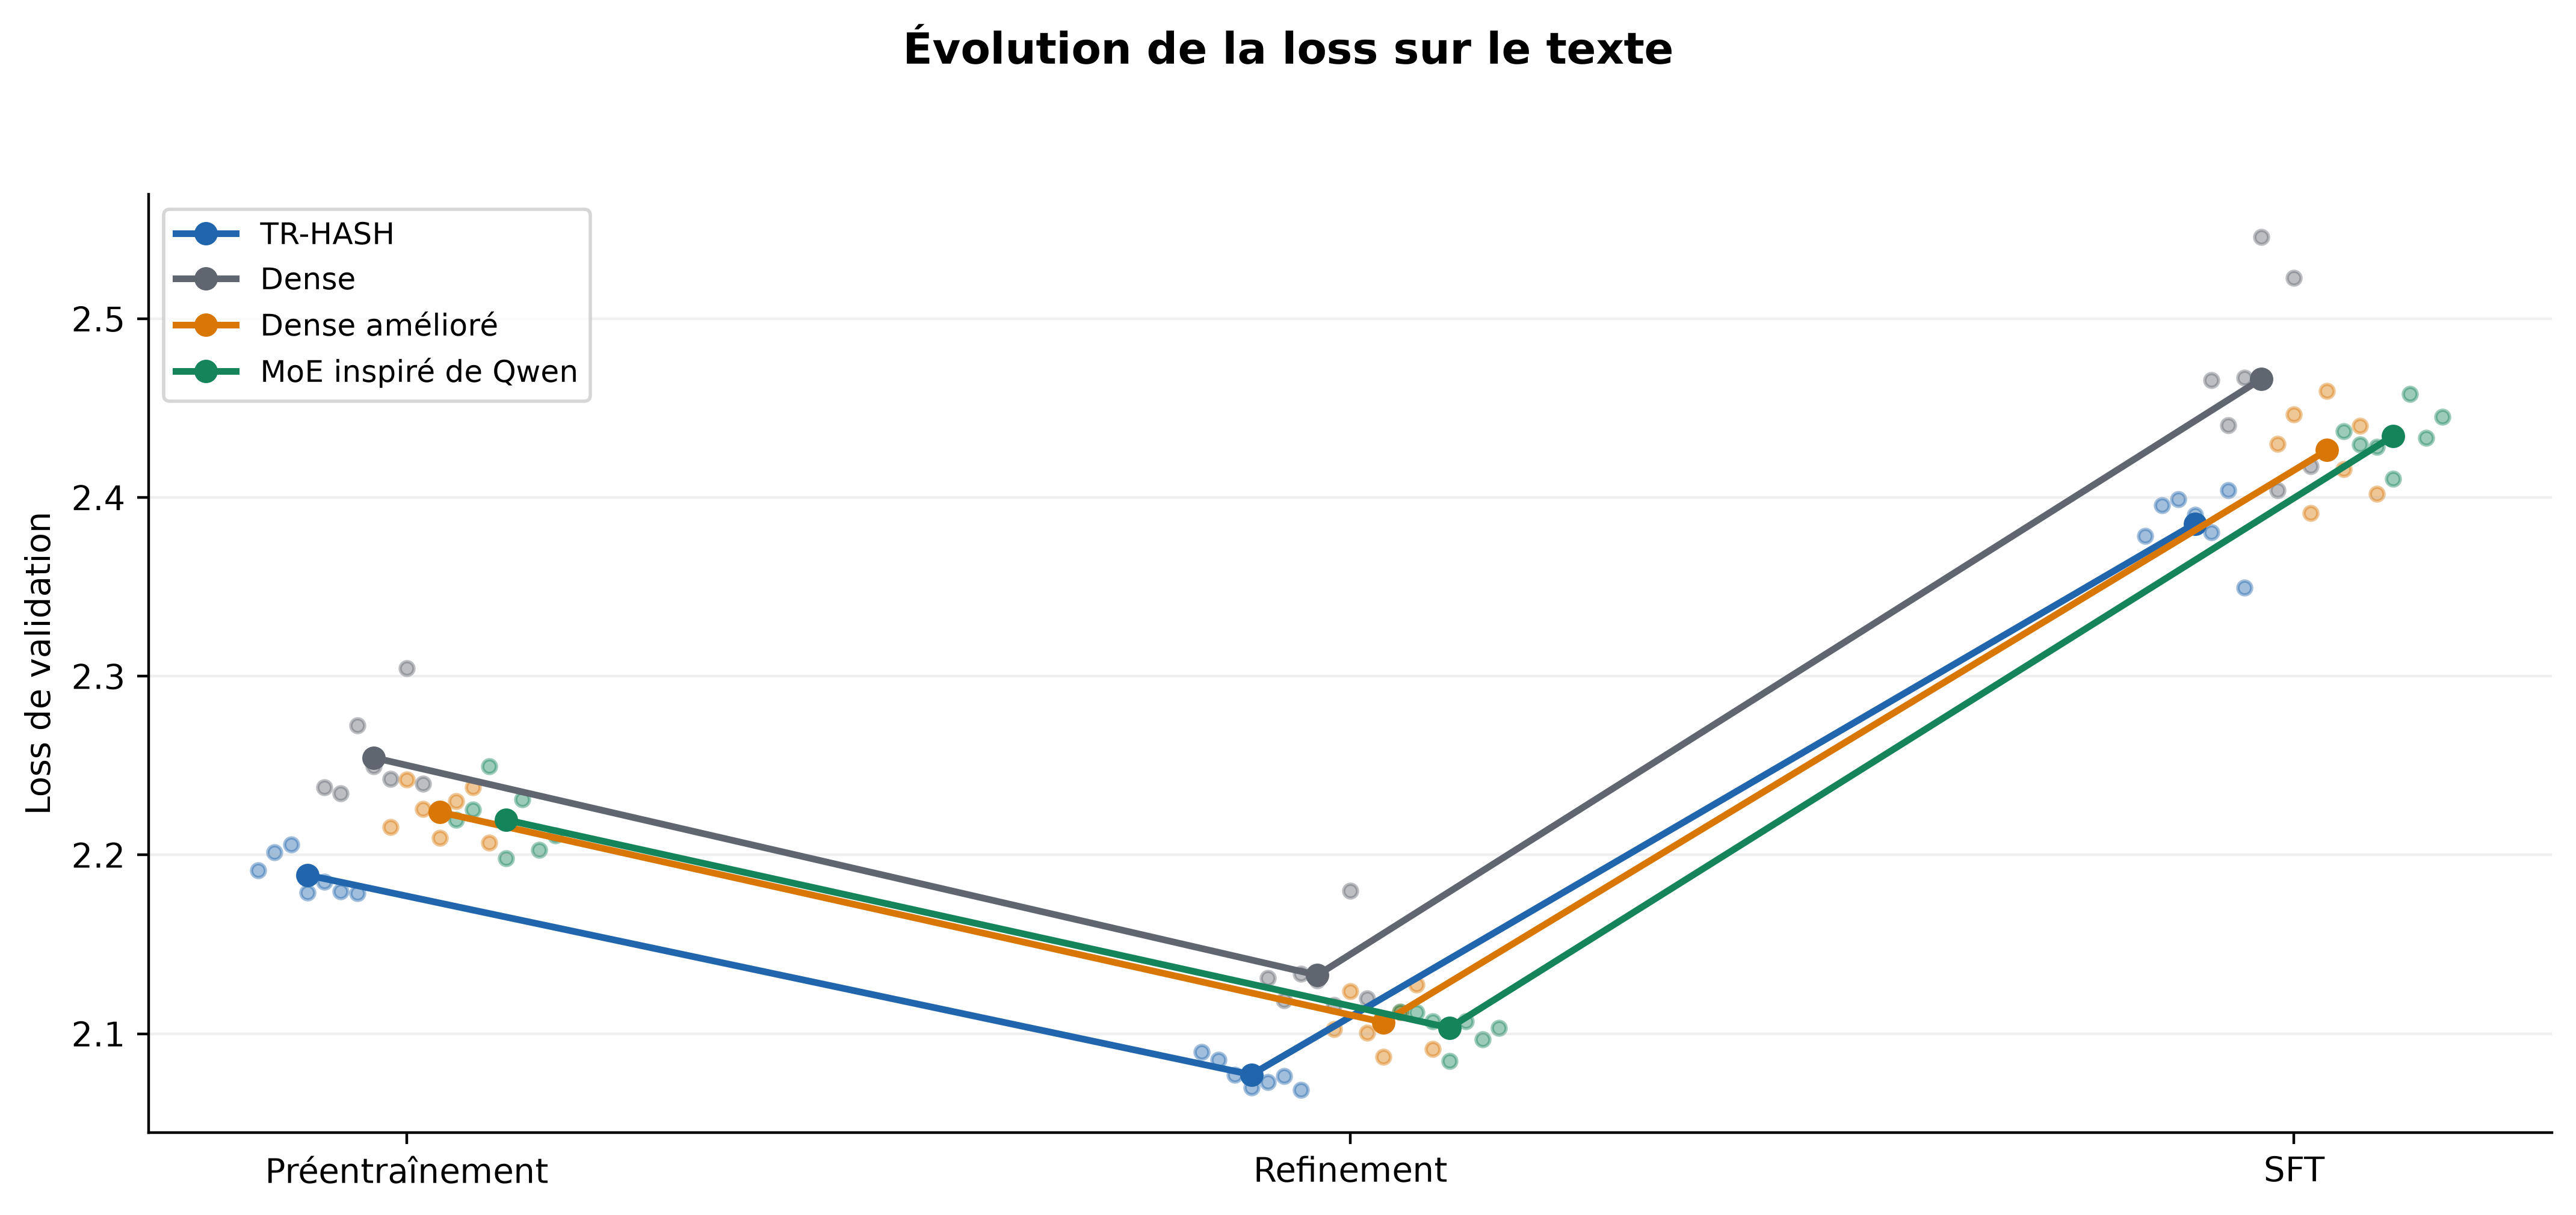

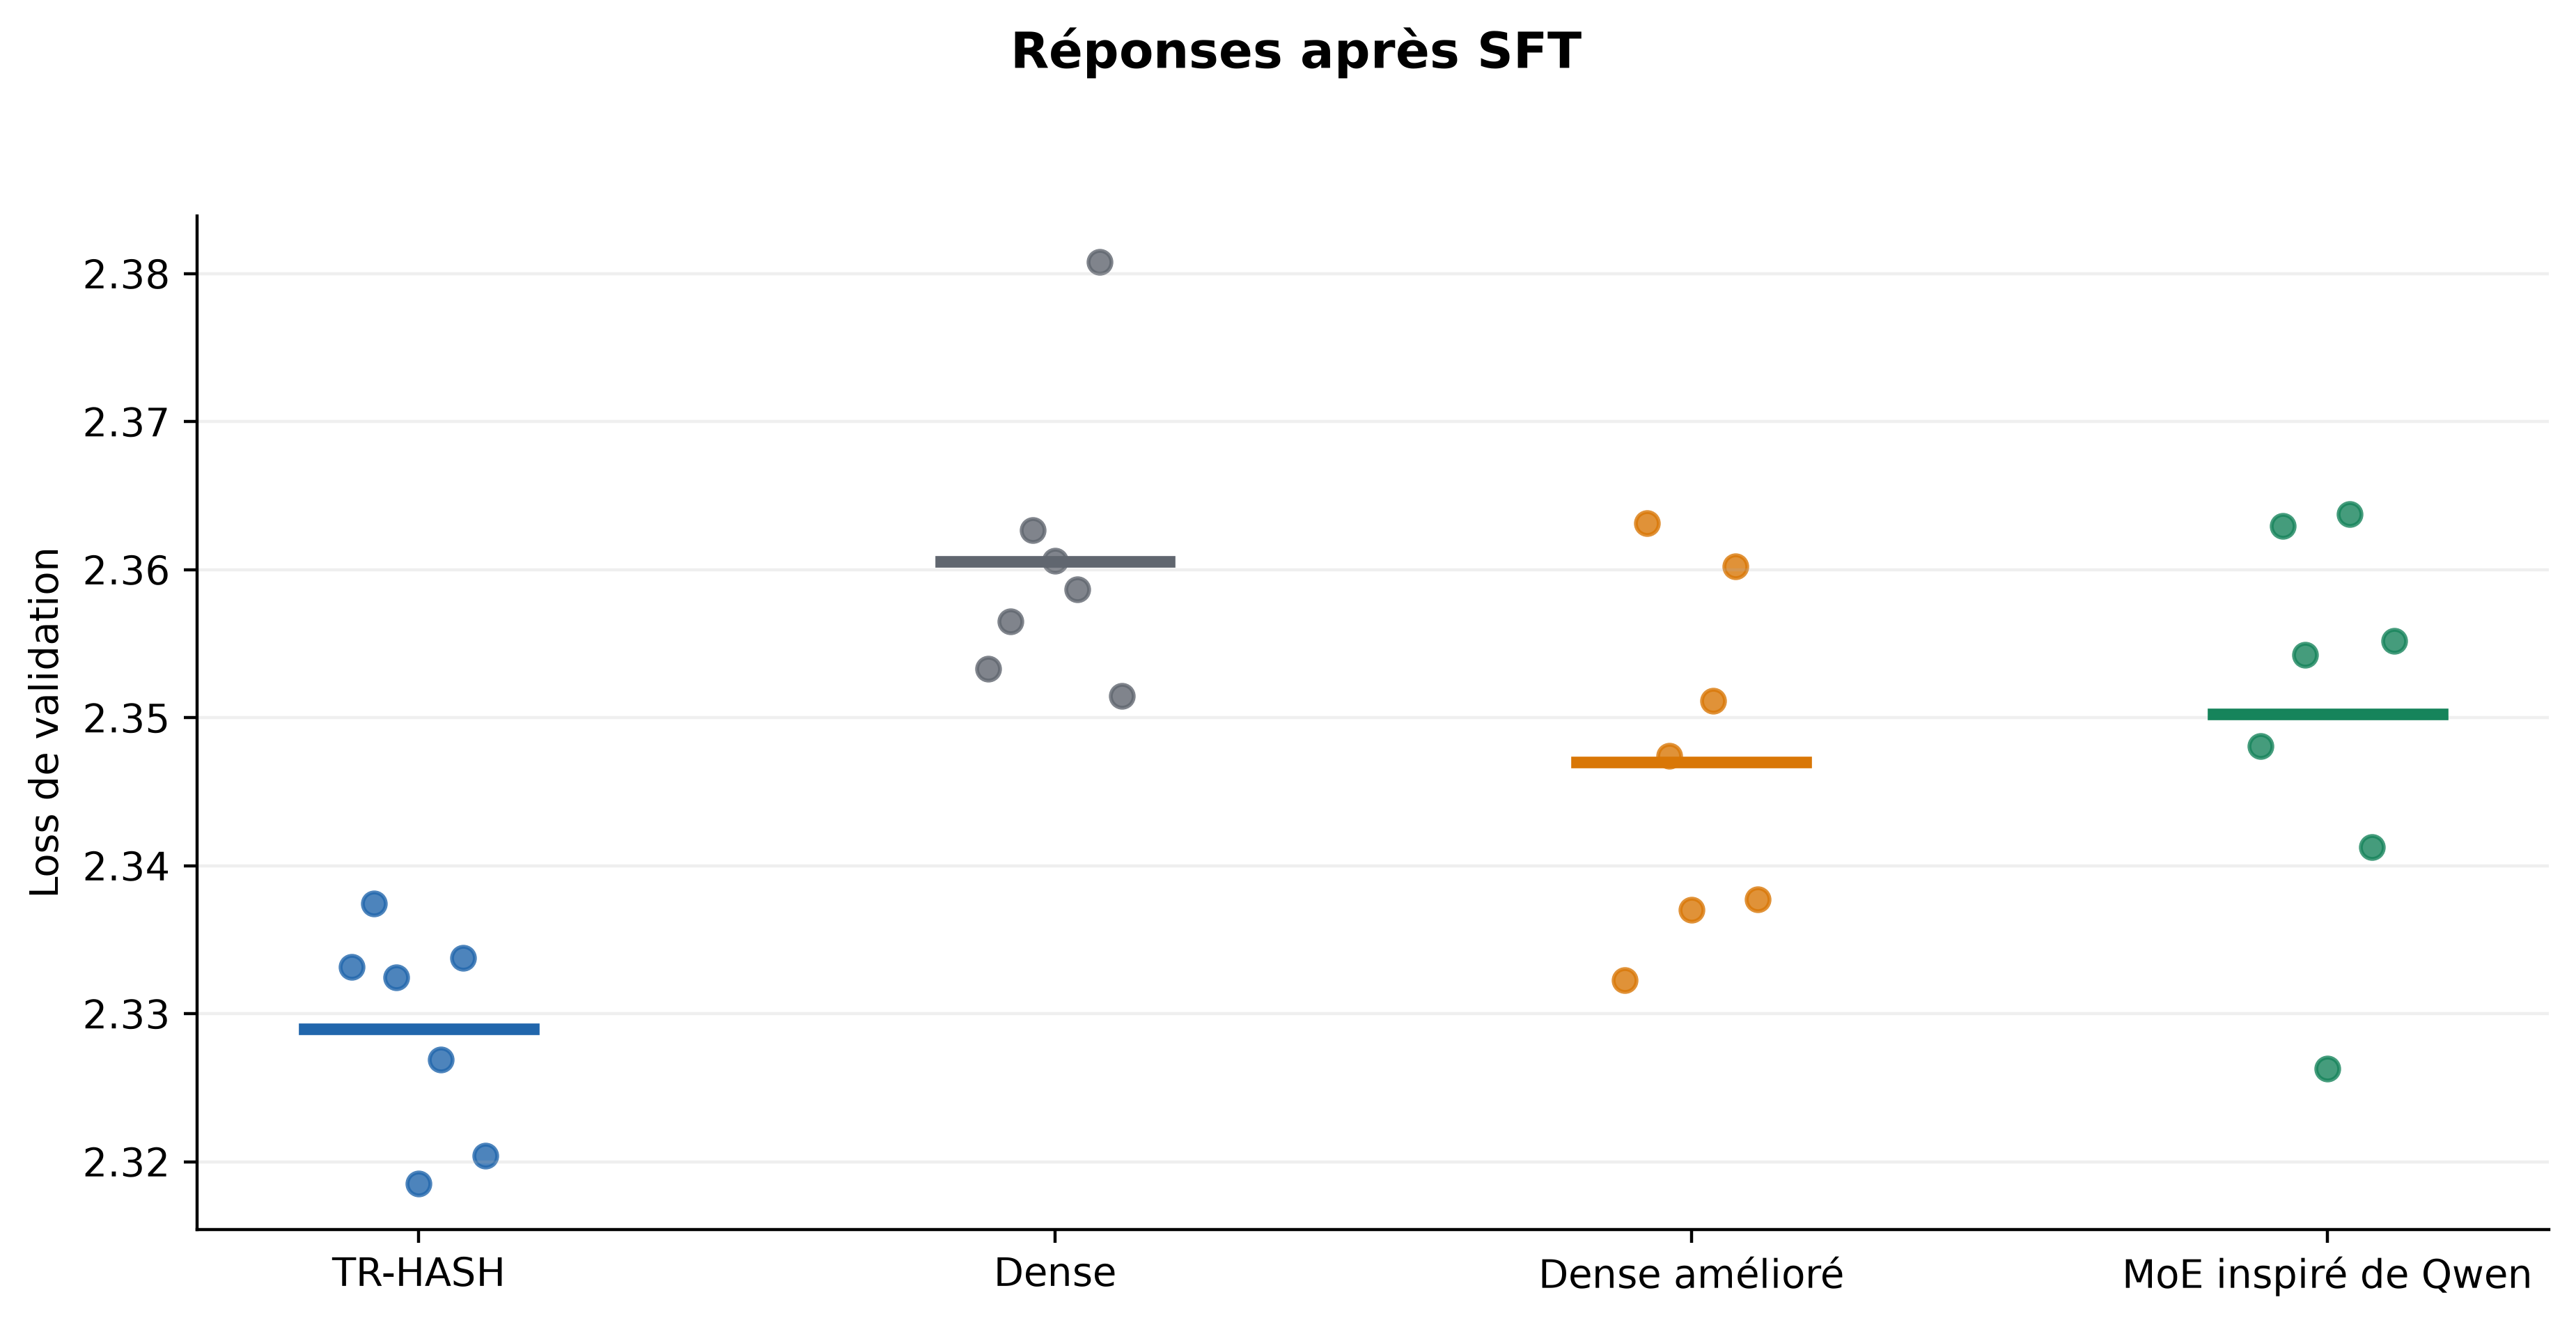

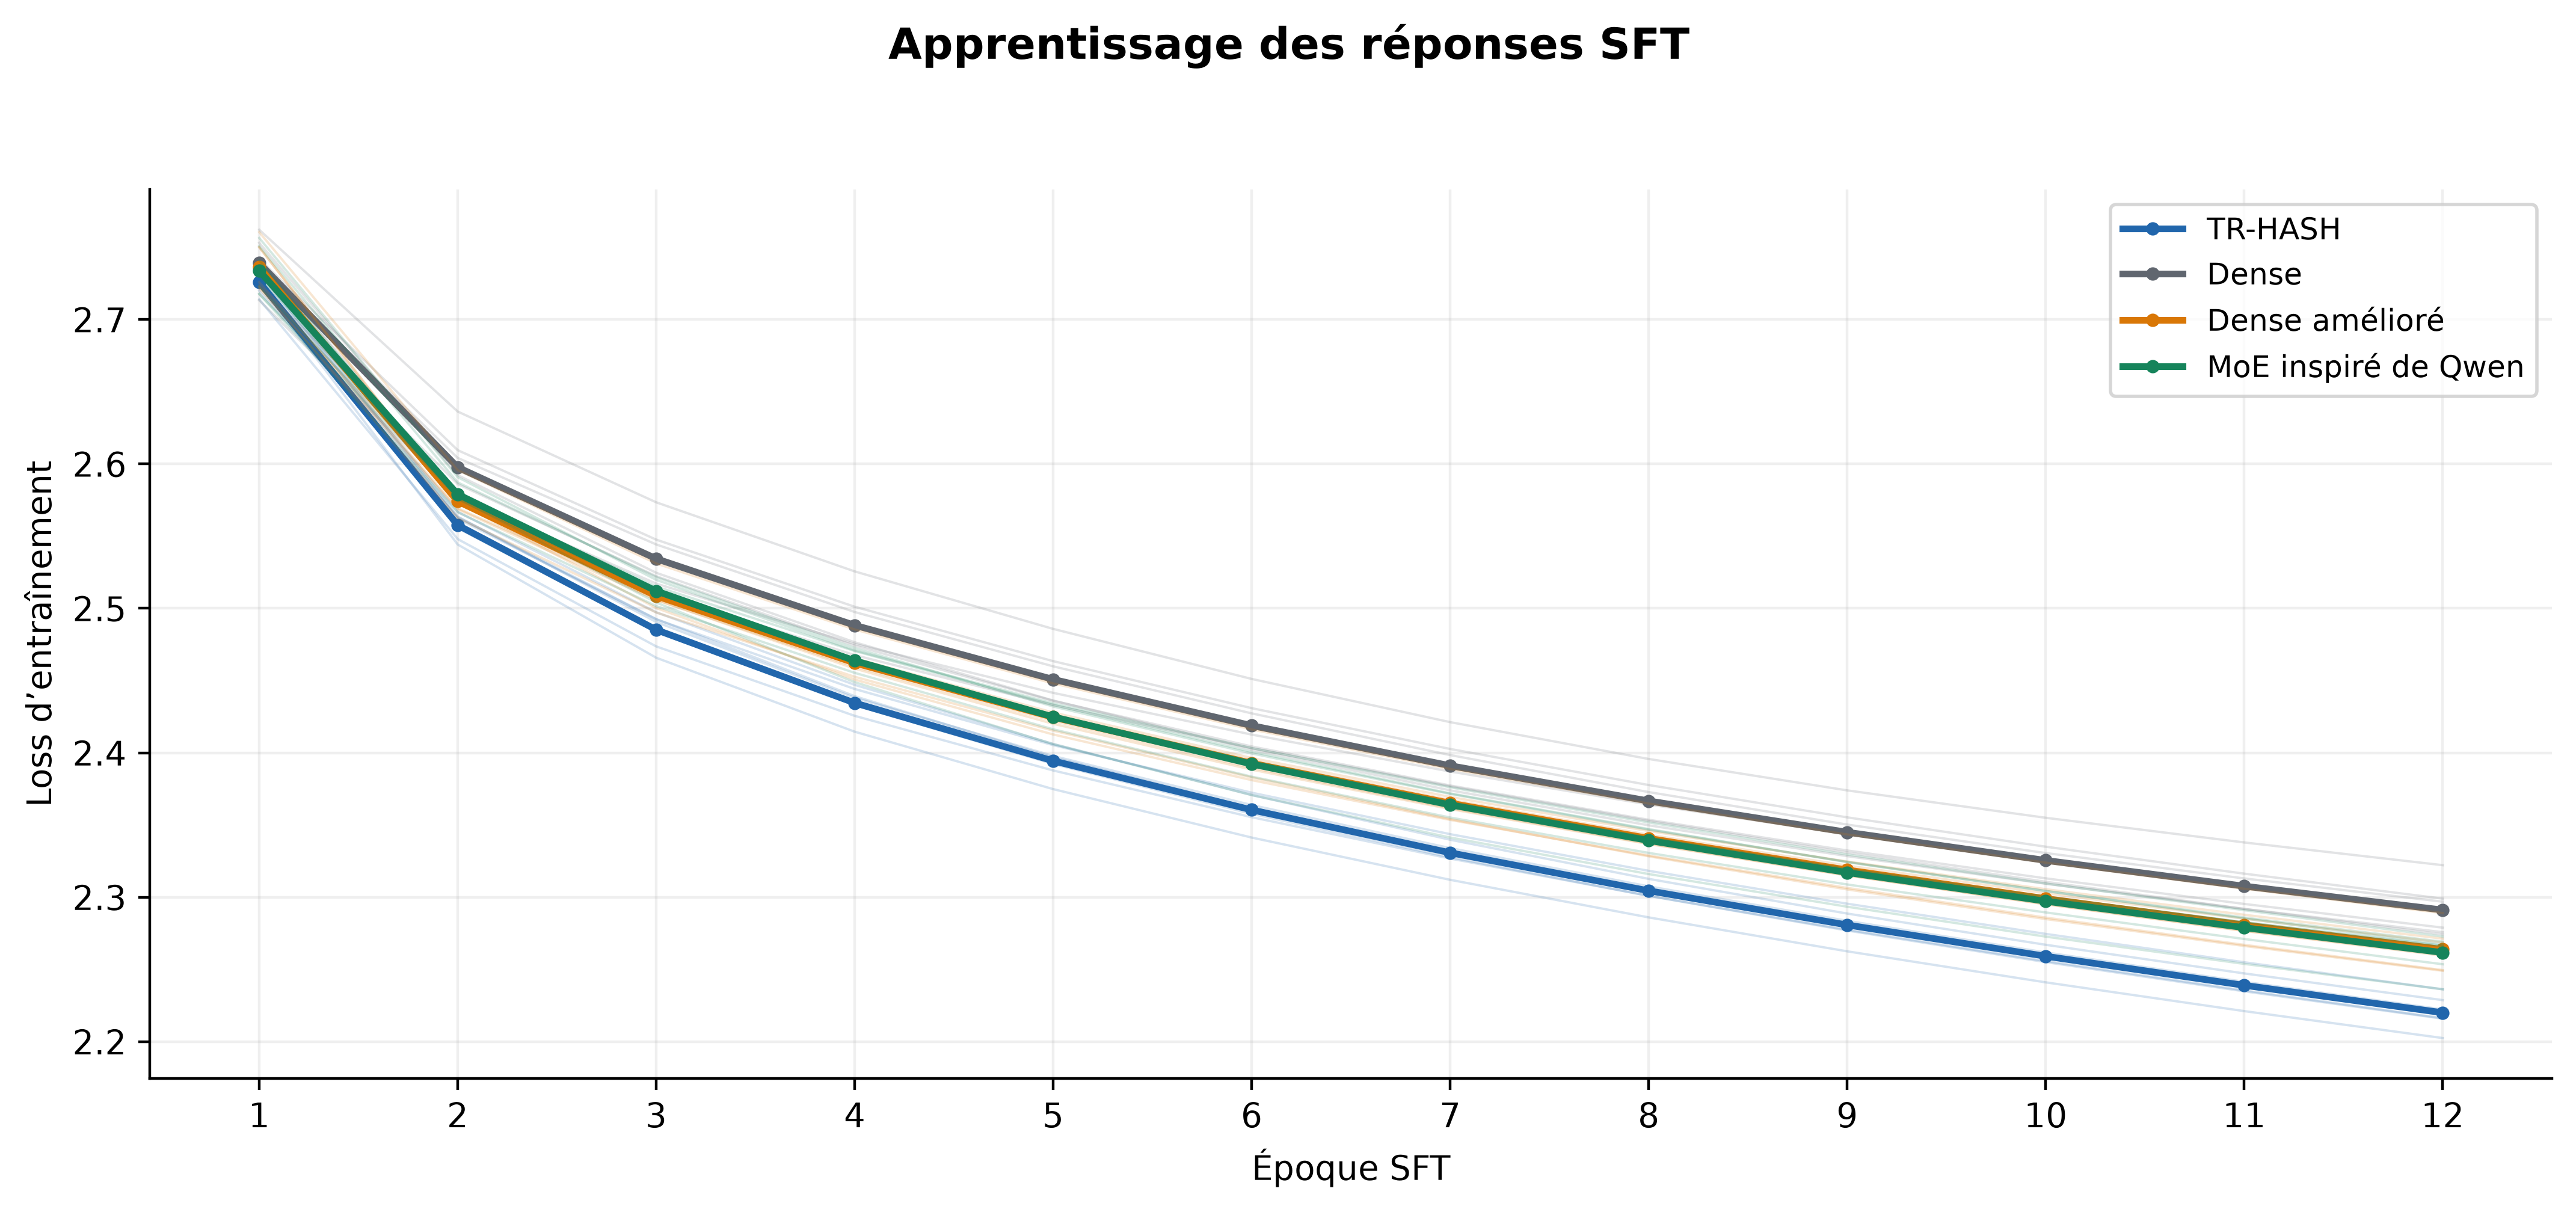

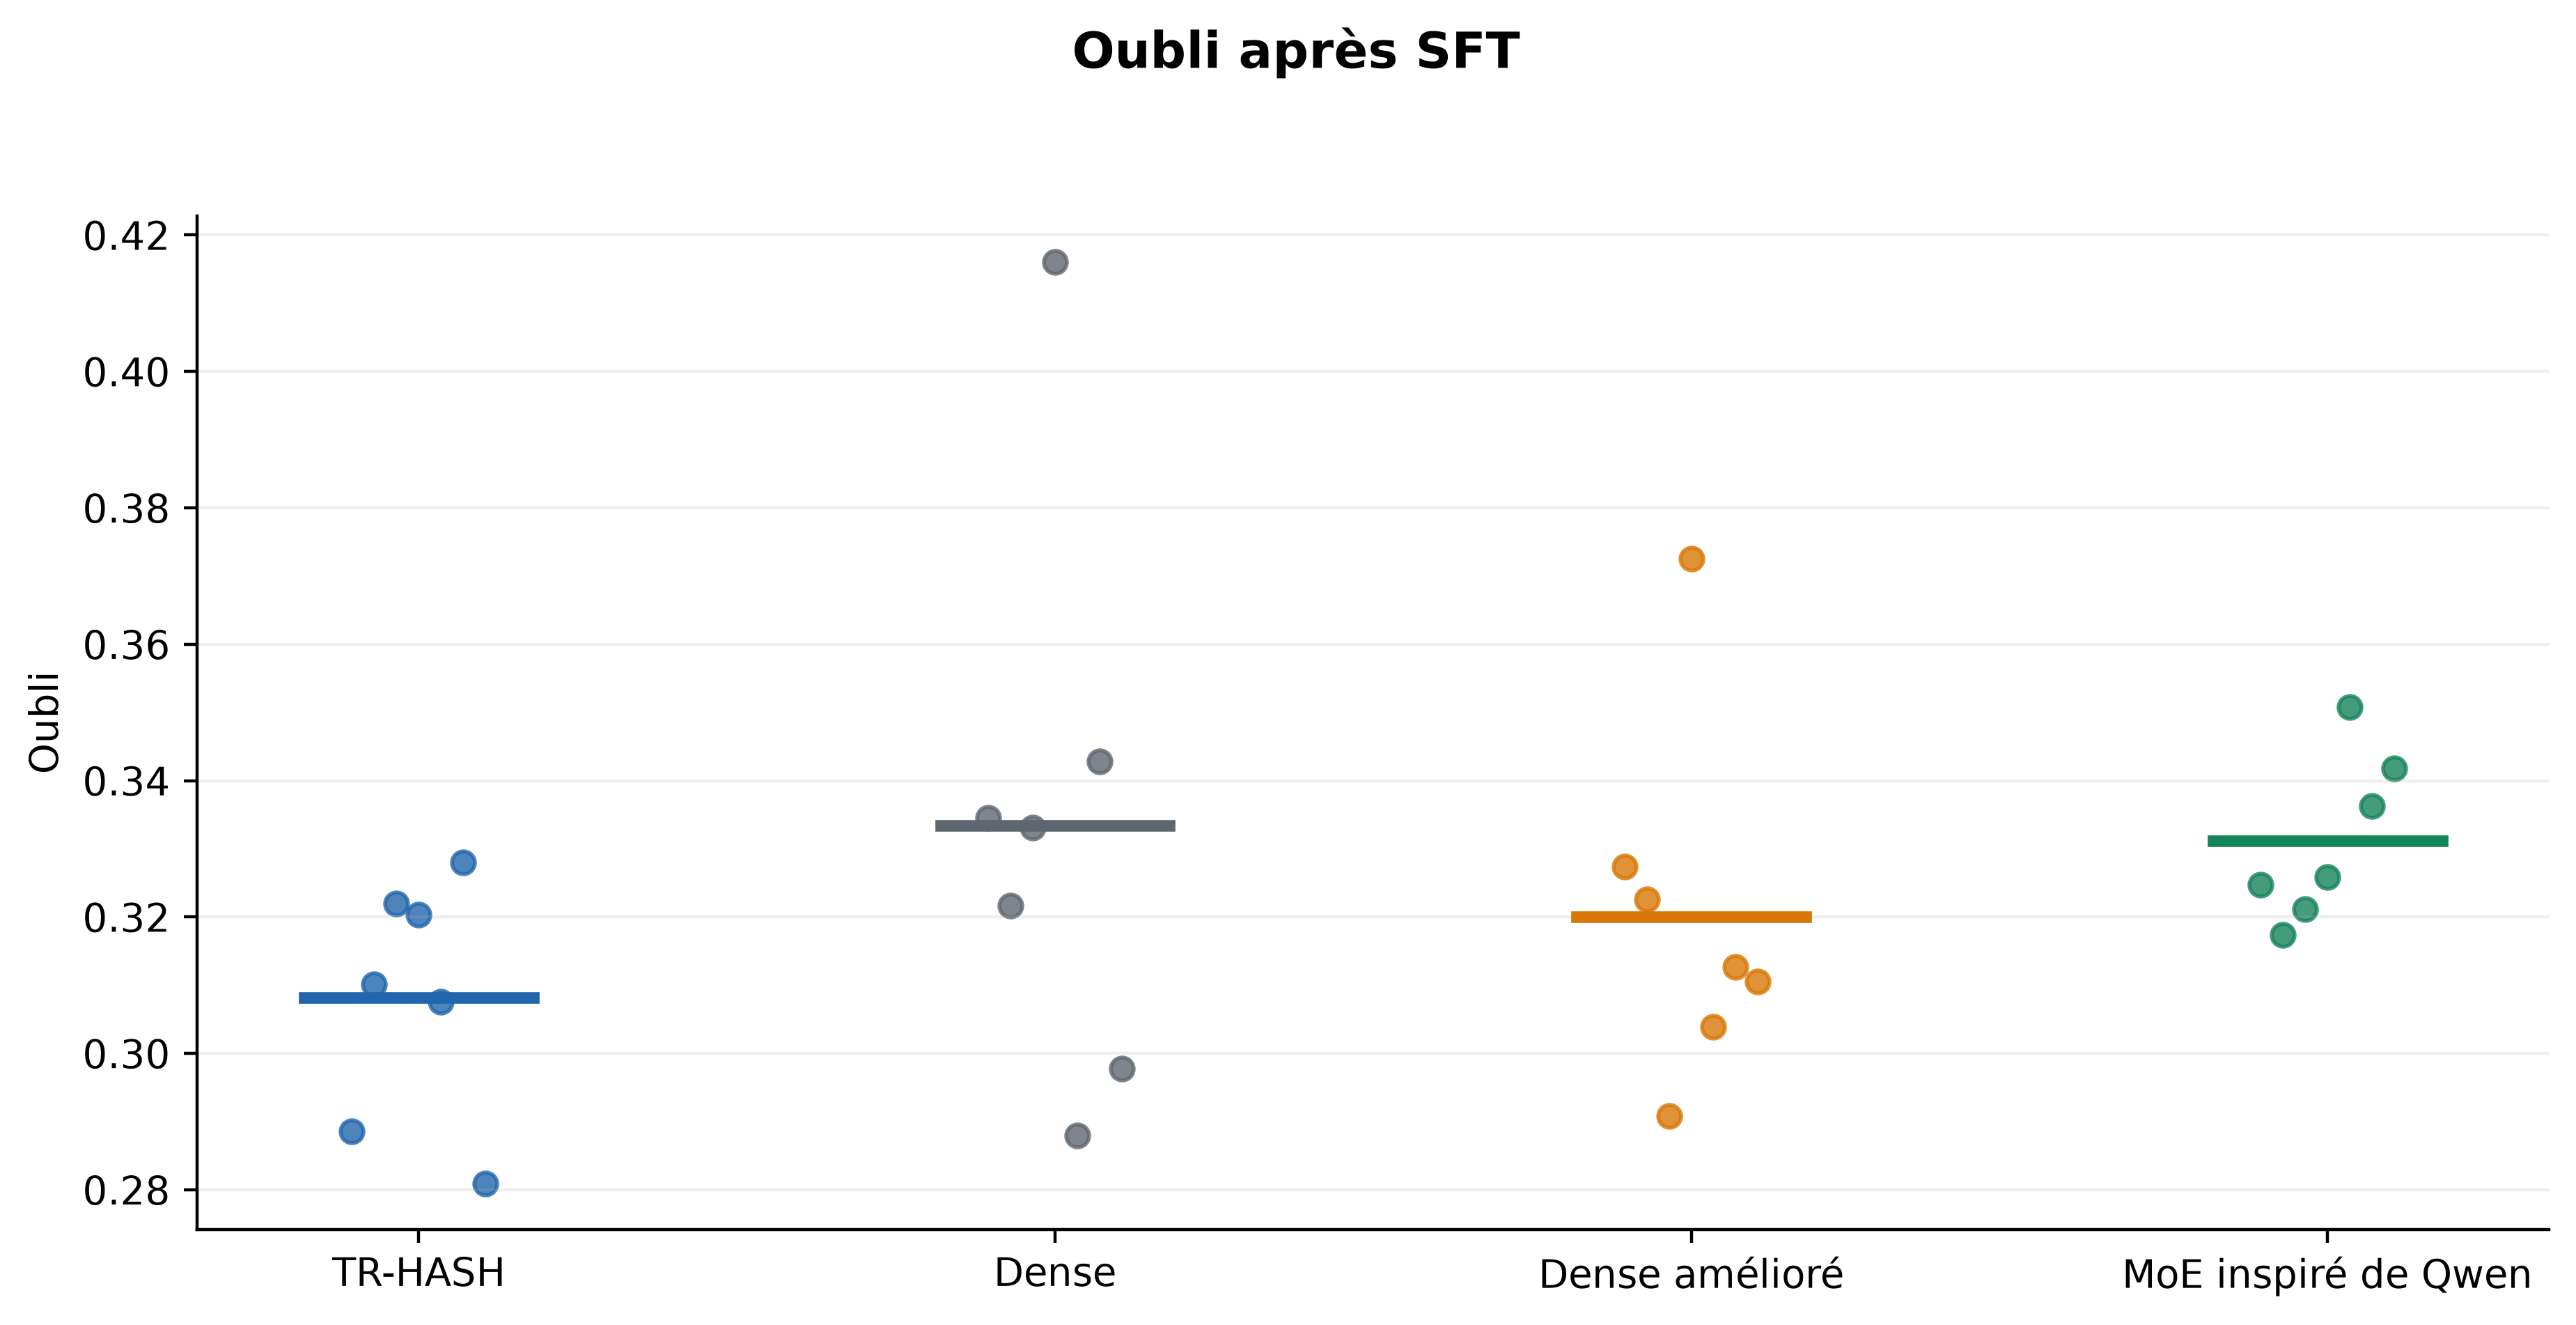

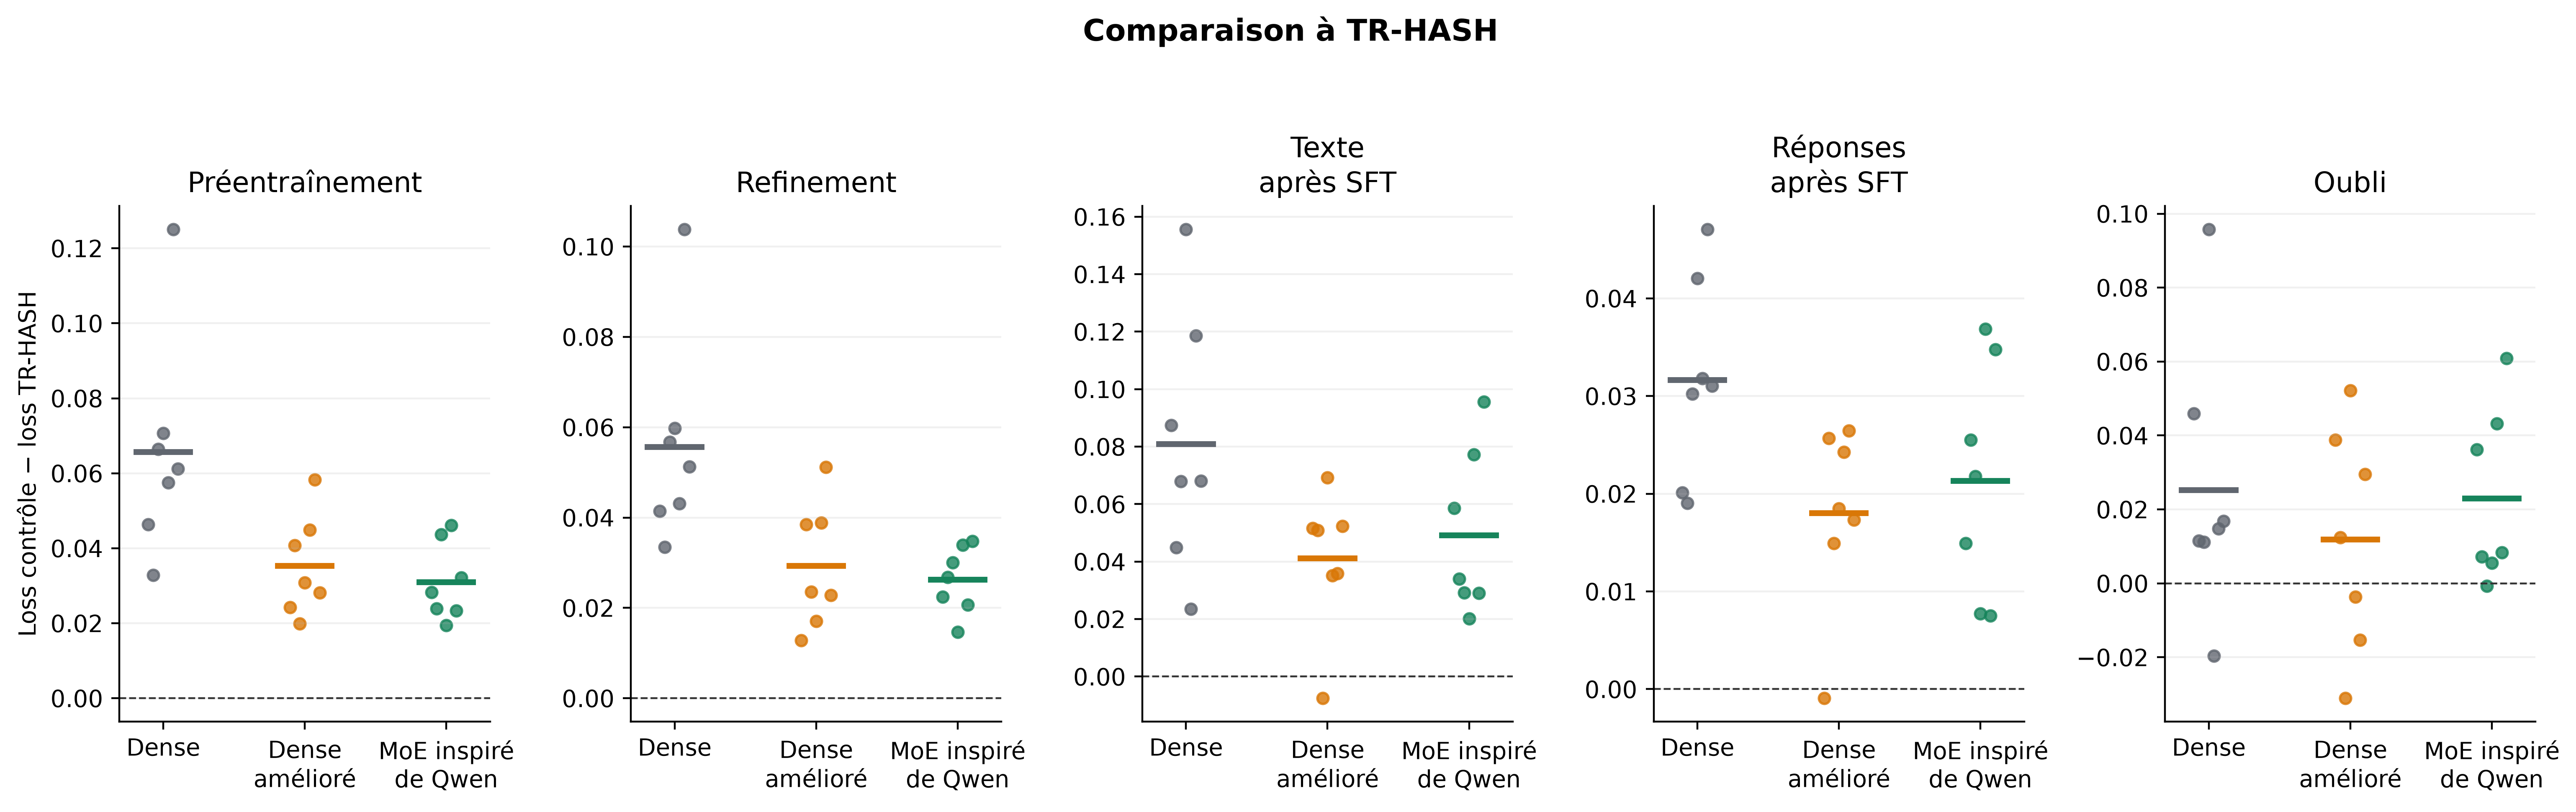

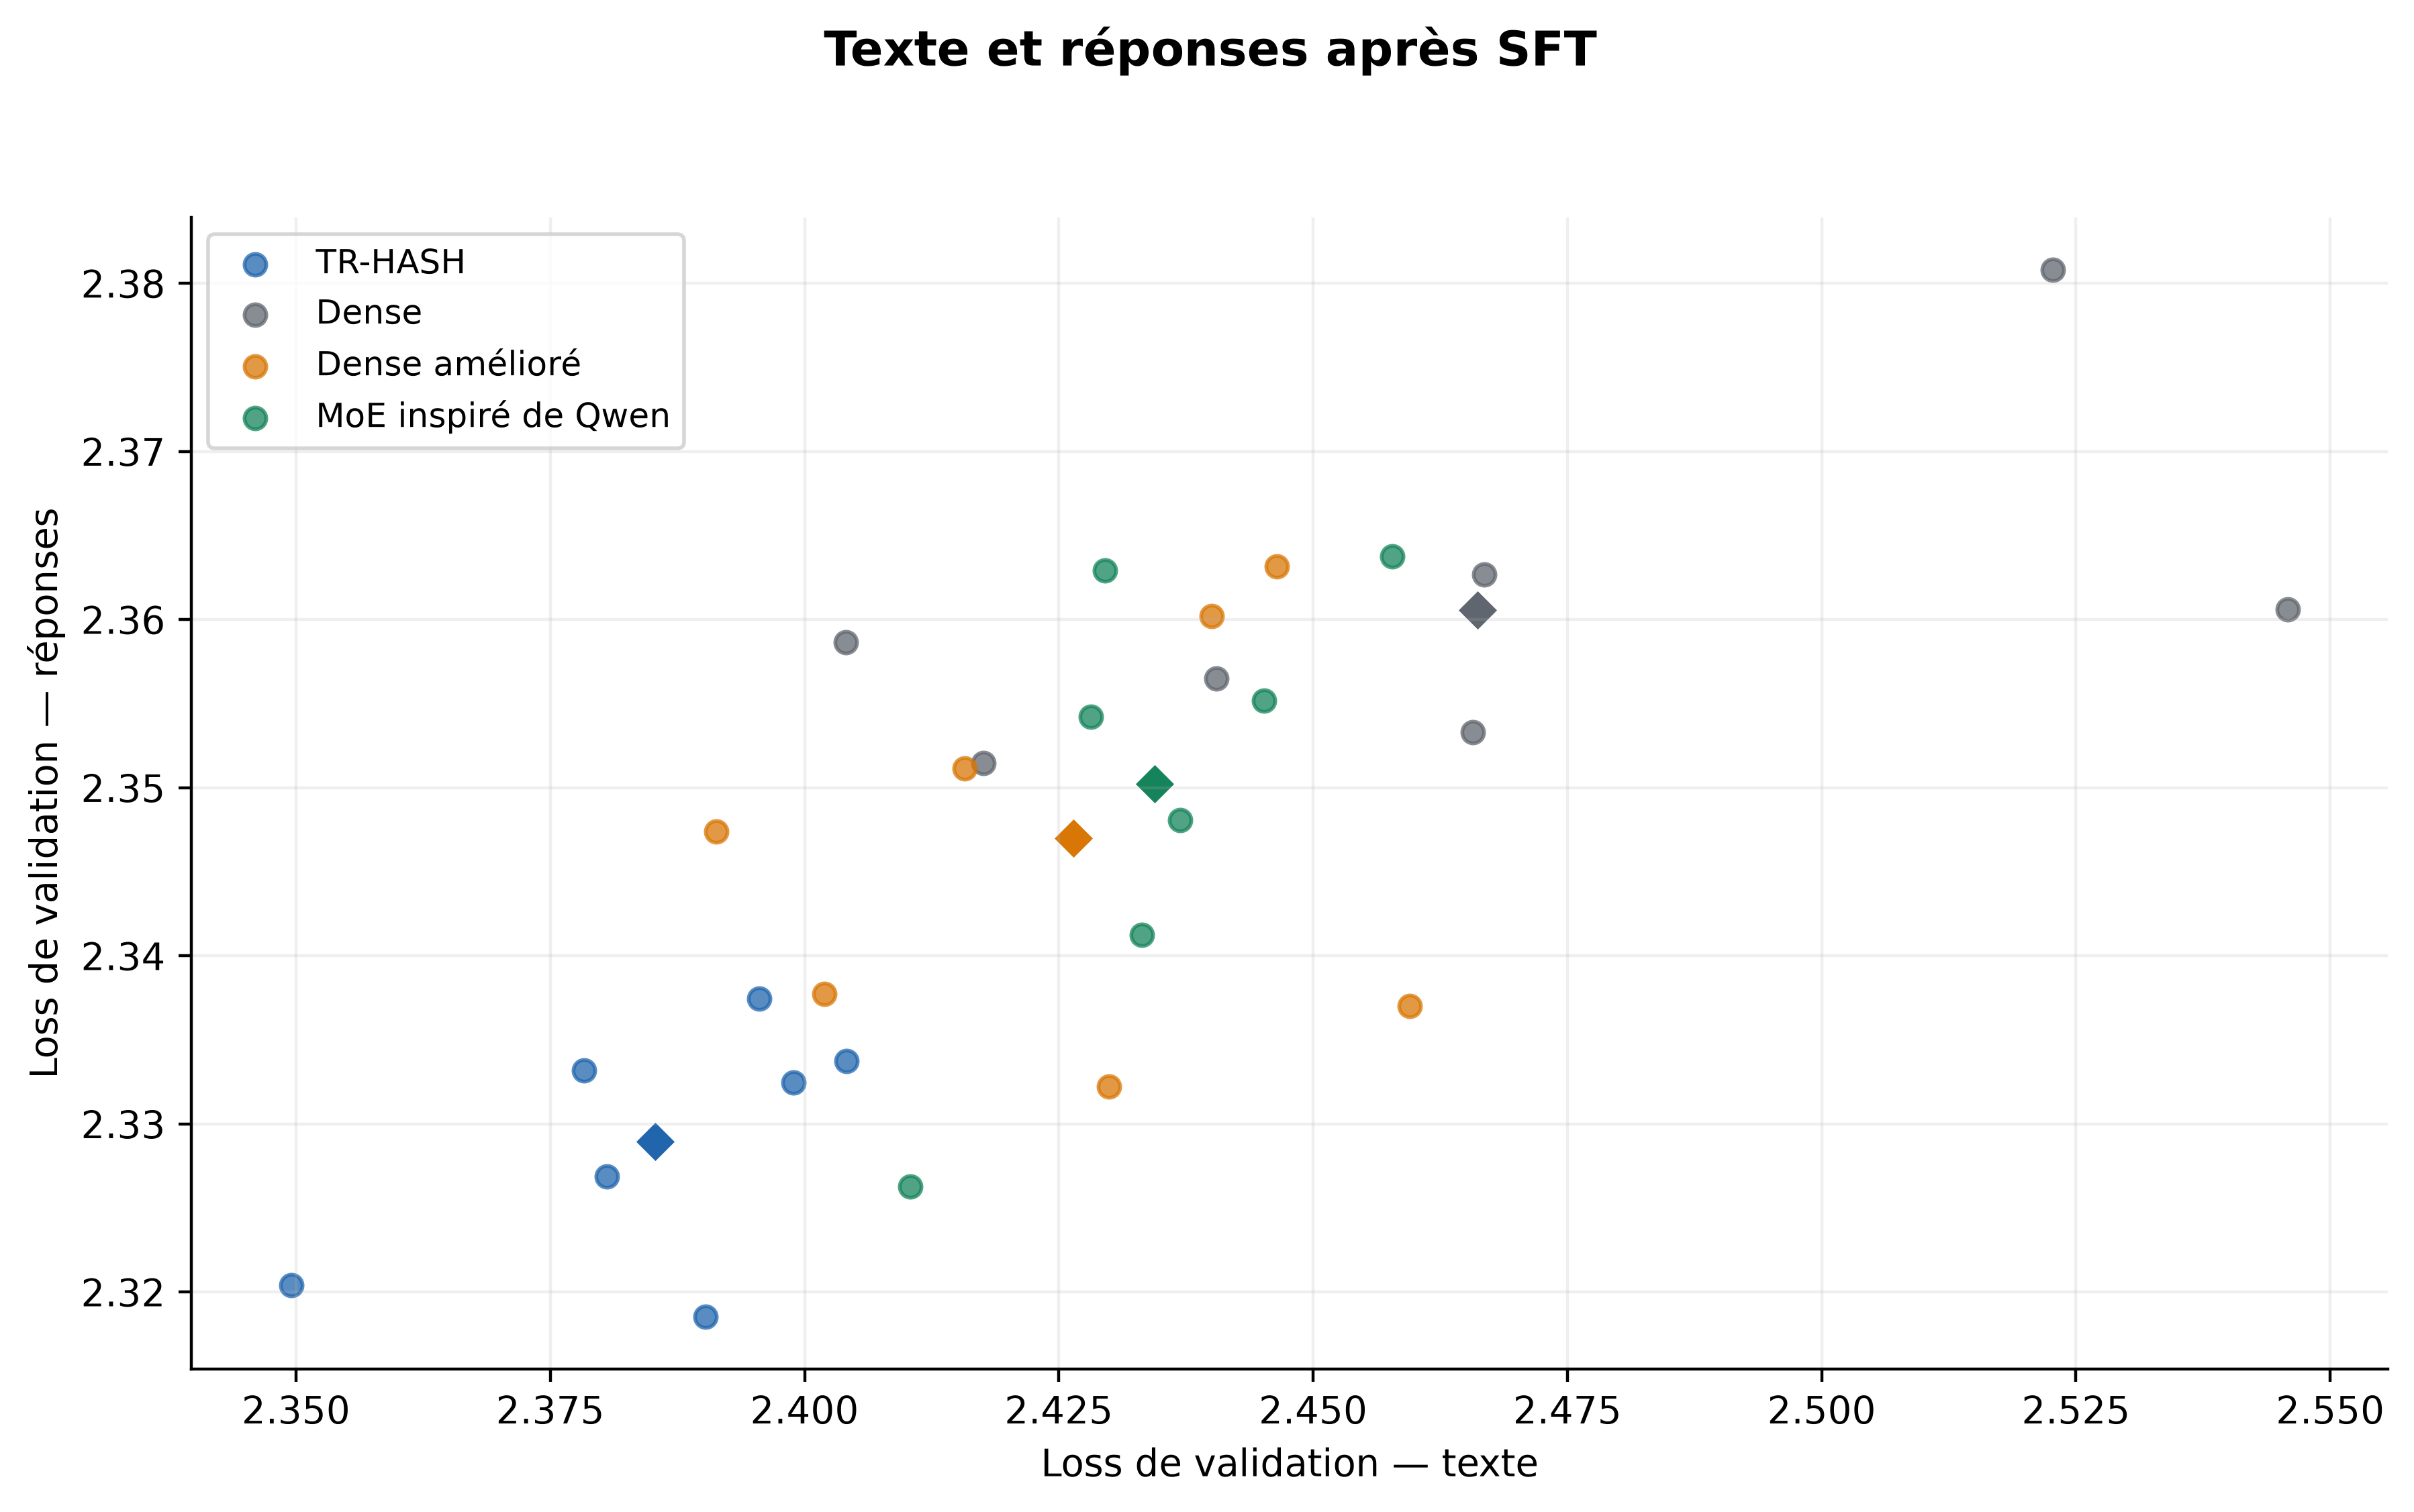

In [7]:
# Résumer les sept seeds avant d'afficher les graphiques.
def tableaux_comparatifs(resultats):
    import pandas as pd

    noms = {
        "tr_hash": "TR-HASH",
        "dense": "Dense",
        "dense_upgraded": "Dense amélioré",
        "learned_moe": "MoE inspiré de Qwen",
    }
    metriques = {
        "lm_pretrain": "Prétrain",
        "lm_refinement": "Refinement",
        "lm_final": "Texte après SFT",
        "reponses_finales": "Réponses SFT",
        "oubli": "Oubli",
    }
    details = pd.DataFrame([
        {"seed": ligne["seed"], "model": ligne["model"], **ligne["metrics"]}
        for ligne in resultats["trajectories"]
    ])
    rangs = details.groupby("seed")[list(metriques)].rank(method="average")
    details["rang_moyen"] = rangs.mean(axis=1)
    resume = details.groupby("model")[[*metriques, "rang_moyen"]].mean()
    resume = resume.sort_values("rang_moyen", kind="stable")
    resume.insert(0, "Rang", resume["rang_moyen"].rank(method="min").astype(int))
    resume = resume.reset_index().rename(columns={
        "model": "Modèle", "rang_moyen": "Rang moyen", **metriques,
    })
    resume["Modèle"] = resume["Modèle"].map(noms)
    resume = resume[["Rang", "Modèle", "Rang moyen", *metriques.values()]]

    index = {(ligne["model"], ligne["seed"]): ligne["metrics"]
             for ligne in resultats["trajectories"]}
    seeds = resultats["protocol"]["seeds"]
    confrontations = []
    for adversaire in noms:
        if adversaire == "tr_hash":
            continue
        ecarts = [index["tr_hash", seed][m] - index[adversaire, seed][m]
                  for seed in seeds for m in metriques]
        tr_gagne = sum(ecart <= -0.001 for ecart in ecarts)
        autre_gagne = sum(ecart >= 0.001 for ecart in ecarts)
        confrontations.append({
            "Adversaire": noms[adversaire],
            "Victoires TR-HASH": tr_gagne,
            "Victoires adversaire": autre_gagne,
            "Écarts < 0,001": len(ecarts) - tr_gagne - autre_gagne,
        })
    return resume, pd.DataFrame(confrontations), details


saved_results = None
if RUN_DIRECTORY is not None:
    import pandas as pd
    from IPython.display import display, Image, Markdown

    RUN_DIRECTORY = Path(RUN_DIRECTORY).expanduser().resolve()
    saved_results = load_saved_results(RUN_DIRECTORY)
    classement, face_a_face, details = tableaux_comparatifs(saved_results)
    display(Markdown("### Classement général"))
    display(Markdown("Moyennes sur sept seeds. Le classement utilise le rang moyen sur les cinq métriques ; un rang plus faible est meilleur."))
    colonnes_loss = ["Prétrain", "Refinement", "Texte après SFT", "Réponses SFT", "Oubli"]
    display(classement.style.hide(axis="index").format({
        "Rang moyen": "{:.2f}", **{nom: "{:.4f}" for nom in colonnes_loss},
    }).highlight_min(subset=colonnes_loss, color="#e2f3e7"))
    display(Markdown("### TR-HASH face à chaque modèle"))
    display(Markdown("35 comparaisons par adversaire : sept seeds × cinq métriques. Une victoire exige un avantage d’au moins 0,001."))
    display(face_a_face.style.hide(axis="index"))
    display(Markdown("### Graphiques"))
    figure_manifest = render_plots(
        RUN_DIRECTORY,
        output_dir=Path.cwd() / "artifacts/tr_hash/qualification_figures" / RUN_DIRECTORY.name,
    )
    for figure in figure_manifest["files"]:
        if figure["format"] == "png":
            display(Image(filename=figure["path"], width=1000))
else:
    print("Aucun résultat sélectionné.")
